# Notebook 2 of 5 · Detectors: Classifiers, Anomaly Detection, Calibration, Clean SHAP and Cost

**Project:** Confidence-Aware and Adversarially Robust Cyber Threat Analysis Using Explainable Machine Learning and Evidence-Grounded AI Agents · MSc Data Science Final Project · Spoorthi Hosakote Suresh

This notebook is one of five that together make up the project. It contains the original code **and the outputs of the reported run**, plus guidance added for reading, running and presenting it.

| # | Notebook | Parts of the original notebook | Answers | Needs as input |
|---|---|---|---|---|
| 1 | `01_data_foundation` | Part 1 (+ project overview) | O1 (threat model) | CIC-IDS2017 Kaggle dataset |
| 2 | `02_detectors` | Part 2 | baselines for all RQs | output of 1 |
| 3 | `03_adversarial_attacks` | Part 3 | **RQ1** | outputs of 1, 2 |
| 4 | `04_confidence_mechanism` | Parts 4 and 4b | **RQ2** | outputs of 1, 2, 3 |
| 5 | `05_agents_results_deployment` | Parts 5, 6, 7, 7b, 8 | **RQ3, RQ4**, final answers | outputs of 1, 2, 3, 4 |

**How this notebook is organised:** sections 1–5 below explain the notebook (what it does, how to run it, key concepts, methodology, key results). The original project code and outputs follow. A **viva guide** is at the end.

### Setup · presentation helpers
Writes the small flowchart helper used by every flowchart in this notebook. **Run this cell first** if you re-run any flowchart cell on its own.

In [1]:
# Presentation helpers (flowcharts, colours) are written once to a small module, so every Part can use them
import os, sys
from pathlib import Path
PRES_DIR = Path(os.environ.get("IDS_WORK_ROOT", "/kaggle/working")) / "presentation"
PRES_DIR.mkdir(parents=True, exist_ok=True)
(PRES_DIR / "present_lib.py").write_text(r'''"""Presentation helpers for the combined notebook: flowcharts and a shared colour palette."""
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

FILL = {"data": "#DCE9F5", "model": "#E1F0DC", "attack": "#F8DEDB", "policy": "#FFEFD2",
        "agent": "#E9E1F4", "out": "#EFEFEF", "rq": "#FFFFFF", "accept": "#D7EFD7", "flag": "#FFE9B8", "escalate": "#F6C9C4"}
EDGE = {"data": "#3B6EA8", "model": "#4E9A47", "attack": "#C0453F", "policy": "#D9822B",
        "agent": "#7A5DB0", "out": "#7A7A7A", "rq": "#333333", "accept": "#3E8E41", "flag": "#C99100", "escalate": "#B3261E"}
SYSTEM_COLORS = {"A": "#9E9E9E", "B": "#4C72B0", "C": "#DD8452", "D": "#8172B3", "E": "#55A868"}
MODEL_COLORS = {"rf": "#4C72B0", "xgb": "#55A868", "mlp": "#C44E52"}


def _anchor(node, toward):
    x, y, w, h = node[:4]
    tx, ty = toward
    dx, dy = tx - x, ty - y
    if abs(dx) * h >= abs(dy) * w:           # leave through the left or right side
        return (x + (w / 2 + 0.6) * (1 if dx > 0 else -1), y)
    return (x, y + (h / 2 + 0.6) * (1 if dy > 0 else -1))


def flowchart(nodes, edges, size=(15, 6.5), title=None, fontsize=9.5, legend=None):
    """nodes: {key: (x, y, w, h, text, kind)} in a 0-100 x 0-50 canvas (centre coordinates).
    edges: [(from, to, label, rad)] - label and rad optional."""
    fig, ax = plt.subplots(figsize=size)
    ax.set_xlim(0, 100); ax.set_ylim(0, 50); ax.axis("off")
    for k, (x, y, w, h, text, kind) in nodes.items():
        ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.35,rounding_size=1.0",
                                    fc=FILL[kind], ec=EDGE[kind], lw=1.6, zorder=2))
        ax.text(x, y, text, ha="center", va="center", fontsize=fontsize, zorder=3, linespacing=1.25)
    for e in edges:
        a, b = e[0], e[1]
        label = e[2] if len(e) > 2 else ""
        rad = e[3] if len(e) > 3 else 0.0
        pa = _anchor(nodes[a], nodes[b][:2]); pb = _anchor(nodes[b], nodes[a][:2])
        ax.annotate("", xy=pb, xytext=pa, zorder=1,
                    arrowprops=dict(arrowstyle="-|>", color="#444444", lw=1.4, mutation_scale=14,
                                    connectionstyle=f"arc3,rad={rad}"))
        if label:
            mx, my = (pa[0] + pb[0]) / 2, (pa[1] + pb[1]) / 2
            ax.text(mx, my + 1.0 + 6 * abs(rad), label, ha="center", va="bottom", fontsize=fontsize - 1.5,
                    color="#333333", style="italic", zorder=4,
                    bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))
    if legend:
        handles = [plt.Rectangle((0, 0), 1, 1, fc=FILL[k], ec=EDGE[k]) for k in legend]
        ax.legend(handles, list(legend.values()), loc="lower center", ncol=len(legend), frameon=False,
                  fontsize=fontsize - 1, bbox_to_anchor=(0.5, -0.04))
    if title:
        ax.set_title(title, fontsize=fontsize + 3, fontweight="bold", loc="left")
    plt.tight_layout()
    return fig, ax
''')
sys.path.insert(0, str(PRES_DIR))
print("presentation helpers ready:", PRES_DIR / "present_lib.py")

presentation helpers ready: /kaggle/working/presentation/present_lib.py


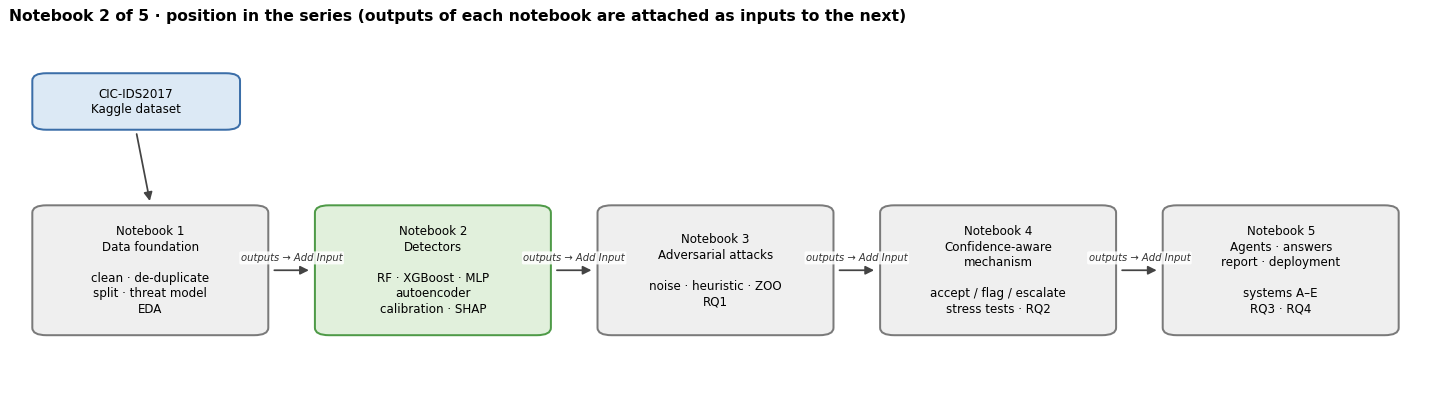

In [ ]:
import os, sys
from pathlib import Path
sys.path.insert(0, str(Path(os.environ.get("IDS_WORK_ROOT", "/kaggle/working")) / "presentation"))
import matplotlib.pyplot as plt
from present_lib import flowchart

# Where this notebook sits in the five-notebook series (highlighted box = this notebook)
nodes = {
    "data": (9, 40, 14, 7, "CIC-IDS2017\nKaggle dataset", "data"),
    "n1": (10, 17, 16, 17, 'Notebook 1\nData foundation\n\nclean · de-duplicate\nsplit · threat model\nEDA', "out"),
    "n2": (30, 17, 16, 17, 'Notebook 2\nDetectors\n\nRF · XGBoost · MLP\nautoencoder\ncalibration · SHAP', "model"),
    "n3": (50, 17, 16, 17, 'Notebook 3\nAdversarial attacks\n\nnoise · heuristic · ZOO\nRQ1', "out"),
    "n4": (70, 17, 16, 17, 'Notebook 4\nConfidence-aware\nmechanism\n\naccept / flag / escalate\nstress tests · RQ2', "out"),
    "n5": (90, 17, 16, 17, 'Notebook 5\nAgents · answers\nreport · deployment\n\nsystems A–E\nRQ3 · RQ4', "out"),
}
edges = [("data", "n1")] + [(f"n{i}", f"n{i+1}", "outputs → Add Input") for i in range(1, 5)]
flowchart(nodes, edges, size=(16, 4.6), title="Notebook 2 of 5 · position in the series (outputs of each notebook are attached as inputs to the next)")
plt.show()

## 1 · What this notebook does

This notebook builds and optimises the **detectors** used everywhere else: three classifiers (Random Forest, XGBoost, MLP), two anomaly detectors (Isolation Forest, autoencoder), probability **calibration**, the clean **SHAP** explanations and the cost of each model. It also checks for **overfitting**.

| Item | Detail |
|---|---|
| Role in the project | Baselines for all research questions; chooses **XGBoost** as the main (policy) detector |
| Input | Output of Notebook 1 (`nb1_data_foundation`) |
| Output folder | `/kaggle/working/nb2_detectors/` (models, calibrators, anomaly reference scores, clean predictions, SHAP values and class prototypes, `models_lib.py`, figures) |
| Run time | estimated 20–40 minutes (measured: tuning ≈ 7 min, imbalance comparison ≈ 3 min; SHAP and the overfitting analysis take most of the rest) |
| Hardware | **GPU T4** (XGBoost and the neural networks use the GPU) · Internet not needed |
| Report sections | 4.2–4.5, 5.1 · Tables 4, 5, 7 · Figures 6, 7 |

## 2 · How to run

**General Kaggle steps (same for every notebook)**
1. On Kaggle, click **Create → New Notebook**, then **File → Import Notebook** and upload this `.ipynb` file.
2. In the right-hand panel, open **Session options** and set the **Accelerator** and **Internet** as listed below.
3. Click **+ Add Input** and attach the inputs listed below. Outputs of your earlier notebooks are found under **Your Work → Notebooks**: choose the notebook and attach its latest **output** version.
4. Click **Save Version → Save & Run All (Commit)**. Running as a saved version keeps the files in `/kaggle/working/` as this notebook's **output**, which the next notebook attaches.
5. When the run finishes, open the version and check the **Final checks** section (every row should show ✔).

**Why this works.** Every Part starts from a clean memory state and finds what it needs by file name, first in `/kaggle/working/` and then anywhere under `/kaggle/input/`. Attached outputs are therefore found automatically; no paths need to be edited.

**For the viva you do not need to re-run anything.** This file already contains every output of the reported run, so all tables and figures can be shown immediately.

**Settings for this notebook**

| Setting | Value |
|---|---|
| Accelerator | GPU T4 ×2 (or ×1) |
| Internet | Off |
| Input to attach | Output of **Notebook 1** |

**Settings you can change** (Section 2.1)

| Constant | Reported value | Meaning |
|---|---|---|
| `TUNE` | True | run the Optuna searches (False = use the default settings) |
| `N_TRIALS` | rf 8, xgb 25, mlp 8 | Optuna trials per model |
| `TUNE_ROWS` | 120,000 | rows used during tuning (speed) |
| `RF_TREES_FINAL` | 200 | trees in the final Random Forest |
| `MLP_EPOCHS`, `MLP_PATIENCE` | 40, 5 | maximum epochs and early-stopping patience |
| `CAL_METHODS` | temperature, dirichlet | calibration methods compared by 5-fold CV |
| `ANOMALY_ALPHA` | 0.05 | conformal p-value below which a flow is anomalous |
| `PROTO_PER_FAMILY` | 300 | training flows per family for SHAP class prototypes |

## 3 · Key concepts and techniques

| Concept | In plain words | Why it is used here | Section |
|---|---|---|---|
| Random Forest | Many decision trees on bootstrap samples, averaged | Strong tabular baseline; exact TreeSHAP | 2.5 |
| XGBoost | Trees added one by one, each correcting the previous ones (gradient boosting) | Best clean model and cheapest explanations (0.32 ms per flow) → main detector | 2.5 |
| MLP | Neural network: Linear → BatchNorm → ReLU → Dropout layers, AdamW, early stopping | Differentiable model, tests whether behaviour differs from trees | 2.1b, 2.5 |
| Optuna (TPE) | Bayesian search that proposes promising hyperparameters from earlier trials | Explicit hyperparameter optimisation; starts from a default trial | 2.3 |
| Internal validation split | 80/20 split of the training subsample | Tuning never touches the calibration, threshold or test sets | 2.2–2.4 |
| Class weights vs SMOTE | Weight rare classes / oversample them | Chosen per model by validation macro-F1 | 2.4 |
| Port ablation | Train with and without port features | Shows the lab-specific shortcut adds only +0.0002 | 2.4 |
| Calibration (temperature, Dirichlet) | Rescale predicted probabilities so 0.9 confidence means 90 % correct | Confidence is evidence in the mechanism | 2.7 |
| NLL / ECE | Log-loss / expected calibration error | Measure calibration quality | 2.7 |
| Isolation Forest | Isolates unusual points with random splits | Anomaly baseline (AUROC 0.895) | 2.8 |
| Autoencoder | Network that reconstructs benign traffic; high error = unusual | Anomaly detector used later (AUROC 0.976) | 2.8 |
| Conformal p-value | Share of benign calibration flows at least as unusual as this flow | Puts anomaly evidence on a known scale (≈ 5 % false alarms at p < 0.05) | 2.8 |
| Macro-F1 + bootstrap CI | Mean F1 over families, with 95 % confidence interval | Fair under extreme imbalance; shows uncertainty | 2.9 |
| SHAP (TreeSHAP, expected gradients) | Contribution of each feature to a prediction | Clean baseline for RQ1; class prototypes for Notebook 4 | 2.10 |
| Overfitting checks | Train vs test gap, learning curves, boosting loss | Evidence that results are not inflated | 2.14 |

## 4 · Methodology at a glance

| Step | What happens | Why | Section |
|---|---|---|---|
| Load | Notebook 1 data; internal 80/20 split of the training subsample | Tuning data separate from all evaluation sets | 2.2 |
| Tune | Optuna: RF 8, XGB 25, MLP 8 trials; default configuration as first trial | Explicit hyperparameter optimisation | 2.3 |
| Imbalance + port | Class weights vs SMOTE per model; with vs without port | Evidence-based choices | 2.4 |
| Final fit | Models refitted on the full training subsample | Final detectors | 2.5 |
| Calibrate | Temperature vs Dirichlet by 5-fold CV NLL on `cal` | Trustworthy confidence | 2.7 |
| Anomaly detectors | Trained on benign flows only; conformal p-values | Independent evidence for the mechanism | 2.8 |
| Evaluate | Test set evaluated once; bootstrap CIs; confusion matrices | Honest clean performance | 2.9 |
| Explain | Clean SHAP and class prototypes | Baseline for RQ1, indicator for RQ2 | 2.10 |
| Cost | Latency, model size, SHAP cost | Input to RQ4 | 2.11 |
| Overfitting | Gap with the same class mix, learning curves, boosting loss | Realism check | 2.14 |

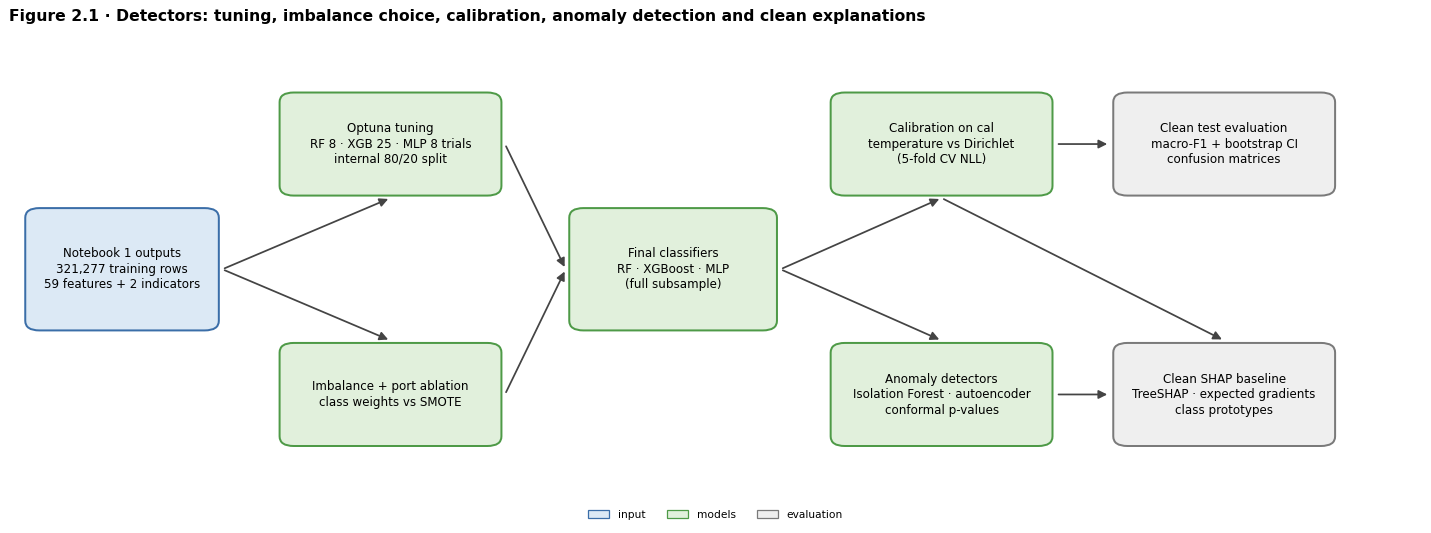

In [ ]:
import os, sys
from pathlib import Path
sys.path.insert(0, str(Path(os.environ.get("IDS_WORK_ROOT", "/kaggle/working")) / "presentation"))
import matplotlib.pyplot as plt
from present_lib import flowchart
# Notebook 2 at a glance: from the leakage-safe data of Notebook 1 to calibrated, explained detectors
nodes = {
    "in":   (8, 25, 13, 12, "Notebook 1 outputs\n321,277 training rows\n59 features + 2 indicators", "data"),
    "tune": (27, 38, 15, 10, "Optuna tuning\nRF 8 · XGB 25 · MLP 8 trials\ninternal 80/20 split", "model"),
    "imb":  (27, 12, 15, 10, "Imbalance + port ablation\nclass weights vs SMOTE", "model"),
    "fit":  (47, 25, 14, 12, "Final classifiers\nRF · XGBoost · MLP\n(full subsample)", "model"),
    "cal":  (66, 38, 15, 10, "Calibration on cal\ntemperature vs Dirichlet\n(5-fold CV NLL)", "model"),
    "ano":  (66, 12, 15, 10, "Anomaly detectors\nIsolation Forest · autoencoder\nconformal p-values", "model"),
    "eval": (86, 38, 15, 10, "Clean test evaluation\nmacro-F1 + bootstrap CI\nconfusion matrices", "out"),
    "shap": (86, 12, 15, 10, "Clean SHAP baseline\nTreeSHAP · expected gradients\nclass prototypes", "out"),
}
edges = [("in", "tune"), ("in", "imb"), ("tune", "fit"), ("imb", "fit"), ("fit", "cal"), ("fit", "ano"),
         ("cal", "eval"), ("ano", "shap"), ("cal", "shap")]
flowchart(nodes, edges, size=(16, 6), title="Figure 2.1 · Detectors: tuning, imbalance choice, calibration, anomaly detection and clean explanations",
          legend={"data": "input", "model": "models", "out": "evaluation"})
plt.show()


## 5 · Key results to remember

| Result | Value |
|---|---|
| Tuning (best validation macro-F1) | RF **0.9828** (8 trials) · XGB **0.9802** (25) · MLP **0.7616** (8, class weights) |
| Imbalance (val macro-F1, weights vs SMOTE) | RF 0.9829 vs 0.9836 · XGB 0.9823 vs 0.9773 · **MLP 0.7772 → 0.9724 with SMOTE** |
| Port ablation | 0.9823 → 0.9825 (+0.0002): port excluded |
| Calibration | Dirichlet for all three; XGB CV NLL 0.0052 (temperature) vs 0.0023 (Dirichlet); ECE 0.0006 → 0.0001 |
| Anomaly detection | Autoencoder AUROC **0.976** (Isolation Forest 0.895); false-alarm rate 5.1 % at α = 0.05 |
| Clean test macro-F1 [95 % CI] | **XGB 0.956 [0.950, 0.961]** · RF 0.946 [0.939, 0.954] · MLP 0.936 [0.929, 0.943] |
| Weakest family | Bot: F1 0.739 (XGB), recall 0.686 |
| SHAP cost per flow | XGB **0.32 ms** · RF 128 ms · MLP 101 ms |
| Overfitting | Train–test gap 0.039–0.049, but ≤ 0.010 with the same class mix → no meaningful overfitting |

---
# Original project code and outputs
Everything below is the project code exactly as in the reported run, with its outputs. Grey **Findings** boxes are generated by the code above them.

<a id="part2"></a>
# Part 2 · Detectors: Classifiers, Anomaly Detection, Calibration, Clean SHAP and Cost

| | |
|---|---|
| **Goal** | Train the classifiers and anomaly detectors, calibrate their confidence, compute clean SHAP explanations and measure their cost. |
| **Answers** | clean baselines for RQ1–RQ4 |
| **Inputs** | Part 1 outputs |
| **Outputs used later** | models, calibrators, conformal anomaly p-values, clean SHAP + class prototypes, cost profile |
| **Run time** | ≈ 40 min (GPU) |

#### Role in the project
This part builds every *component* that the research questions are later asked about. It answers no RQ on its own; it produces the **clean baselines** each RQ is measured against.

| Output of this part | Used to answer |
|---|---|
| Three tuned classifiers (Random Forest, XGBoost, MLP) and their clean macro-F1 | **RQ1** (the "before attack" score), **RQ3** (individual models) |
| Clean SHAP explanations and rankings on the shared evaluation flows | **RQ1** (the "before attack" ranking), **RQ2** (explanation-stability indicator) |
| **Calibrated** classifier confidence | **RQ2** (confidence indicator; uncalibrated confidence is not a valid indicator) |
| Anomaly detectors (Isolation Forest, autoencoder) trained on benign flows only, with conformal p-values | **RQ2** (anomaly indicator), **RQ3** (anomaly-detector baseline) |
| Training time, model size, per-flow latency, throughput, SHAP time | **RQ4** (latency and computational cost) |

#### Protocol (no leakage)
| Data | Used for |
|---|---|
| training subsample → internal 80/20 split (`fit` / `val`) | hyperparameter tuning (Optuna), imbalance strategy, port ablation |
| full training subsample | final model fitting |
| benign flows of the training subsample | anomaly detectors |
| `cal` | probability calibration, anomaly p-value calibration, choice of calibration method and anomaly detector |
| `thr` | untouched here (tuning of the mechanism in Part 4) |
| `test` (natural mix) and `test-lite` | clean evaluation only, reported once |

## 2.1 · Setup and decisions

In [39]:
# Fresh start: this Part reloads everything it needs from the files saved by earlier Parts,
# so memory from the previous Part (e.g. the 2.8 M-row table of Part 1) is released first.
%reset -f
import gc; gc.collect()

0

In [40]:
import os, sys, json, time, platform, warnings, resource, importlib, gc
from pathlib import Path
from datetime import datetime, timezone
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import joblib, sklearn, xgboost as xgb, shap, optuna, torch
from scipy.stats import kendalltau
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.metrics import f1_score, average_precision_score, roc_auc_score, confusion_matrix
from IPython.display import display, Markdown
warnings.filterwarnings("ignore"); optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 220)

INPUT_ROOT = Path(os.environ.get("IDS_INPUT_ROOT", "/kaggle/input"))
WORK_ROOT  = Path(os.environ.get("IDS_WORK_ROOT", "/kaggle/working"))
OUT_DIR = WORK_ROOT / "nb2_detectors"; FIG_DIR = OUT_DIR / "figures"; MODEL_DIR = OUT_DIR / "models"
for d in (FIG_DIR, MODEL_DIR): d.mkdir(parents=True, exist_ok=True)
NOTEBOOK_ID = "nb2_detectors_v1"
SEED = 42; rng = np.random.default_rng(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
N_JOBS = -1

# ---------------- Decisions ----------------
CLASSIFIERS = ["rf", "xgb", "mlp"]                 # the "selected intrusion-detection models" of RQ1
ANOMALY_DETECTORS = ["iforest", "autoencoder"]
VAL_FRAC   = 0.20                                  # internal validation split of the training subsample
TUNE       = True
N_TRIALS   = {"rf": 8, "xgb": 25, "mlp": 8}        # Optuna trials per model
TUNE_ROWS  = 120_000                               # rows of the fit split used during tuning (speed)
RF_TREES_FINAL = 200
MLP_EPOCHS = 40; MLP_PATIENCE = 5
CAL_METHODS = ["temperature", "dirichlet"]         # chosen per model by 5-fold CV on `cal`
ANOMALY_ALPHA = 0.05                               # flag a flow as anomalous if its conformal p-value < alpha
SHAP_BACKGROUND = 200                              # background flows for the MLP explainer
PROTO_PER_FAMILY = 300                             # training flows per family for SHAP class prototypes (Part 4)
N_BOOT = 200                                       # bootstrap resamples for confidence intervals

ENV = {"notebook_id": NOTEBOOK_ID, "run_started_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
       "python": platform.python_version(), "device": DEVICE, "torch": torch.__version__, "xgboost": xgb.__version__,
       "shap": shap.__version__, "optuna": optuna.__version__, "scikit-learn": sklearn.__version__,
       "gpu": torch.cuda.get_device_name(0) if DEVICE == "cuda" else "none"}
display(pd.DataFrame(ENV.items(), columns=["item", "value"]))

def findings(rows, meaning=""):
    text = "> #### Findings\n> | Check | Result |\n> |---|---|\n" + "".join(f"> | {a} | {b} |\n" for a, b in rows)
    if meaning: text += f">\n> **Meaning:** {meaning}\n"
    display(Markdown(text))

def savefig(name):
    plt.tight_layout(); plt.savefig(FIG_DIR / name, dpi=200, bbox_inches="tight"); plt.show()

def to_builtin(o):
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, np.floating): return float(o) if np.isfinite(o) else None
    if isinstance(o, np.bool_): return bool(o)
    if isinstance(o, np.ndarray): return o.tolist()
    if isinstance(o, Path): return str(o)
    if isinstance(o, tuple): return list(o)
    raise TypeError(type(o))

def macro_f1(y, p, K):
    cm = np.bincount(np.asarray(y) * K + np.asarray(p), minlength=K * K).reshape(K, K)
    tp = np.diag(cm); prec = tp / np.maximum(cm.sum(0), 1); rec = tp / np.maximum(cm.sum(1), 1)
    f1 = np.where(prec + rec > 0, 2 * prec * rec / np.maximum(prec + rec, 1e-12), 0)
    return float(f1[cm.sum(1) > 0].mean())

def peak_ram_gb():
    return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1e6

,item,value
0,notebook_id,nb2_detectors_v1
1,run_started_utc,2026-10-24T16:06:57+00:00
2,python,3.13.15
3,device,cuda
4,torch,2.11.0+cu128
5,xgboost,3.4.1
6,shap,0.52.0
7,optuna,5.0.0
8,scikit-learn,1.6.1
9,gpu,Tesla T4


### 2.1b · Shared model library
Model classes, calibration, conformal p-values and timing are written to `models_lib.py`, so Parts 3–5 load the saved models and calibrators with exactly the same code.

In [41]:
LIB_SRC = r"""
import time, numpy as np
import torch, torch.nn as nn
from scipy.optimize import minimize_scalar
from scipy.special import softmax, log_softmax

# ------------------------------------------------------------------ neural classifier
class MLP(nn.Module):
    def __init__(self, d_in, n_out, hidden=(256, 128, 64), dropout=0.2):
        super().__init__()
        layers, d = [], d_in
        for h in hidden:
            layers += [nn.Linear(d, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(dropout)]
            d = h
        layers.append(nn.Linear(d, n_out))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

def _batches(n, bs, shuffle, g):
    idx = torch.randperm(n, generator=g) if shuffle else torch.arange(n)
    for i in range(0, n, bs):
        yield idx[i:i + bs]

def torch_logits(model, X, device="cpu", bs=16384):
    model.eval(); out = []
    with torch.no_grad():
        Xt = torch.as_tensor(np.asarray(X, dtype="float32"))
        for i in range(0, len(Xt), bs):
            out.append(model(Xt[i:i + bs].to(device)).cpu().numpy())
    return np.concatenate(out)

def train_mlp(X, y, Xv, yv, n_classes, class_weight=None, hidden=(256, 128, 64), dropout=0.2, lr=1e-3,
              weight_decay=1e-4, batch_size=1024, max_epochs=40, patience=5, seed=42, device="cpu", score_fn=None):
    torch.manual_seed(seed); g = torch.Generator().manual_seed(seed)
    model = MLP(X.shape[1], n_classes, hidden, dropout).to(device)
    w = torch.as_tensor(class_weight, dtype=torch.float32, device=device) if class_weight is not None else None
    loss_fn = nn.CrossEntropyLoss(weight=w)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=2)
    Xt = torch.as_tensor(np.asarray(X, dtype="float32")); yt = torch.as_tensor(np.asarray(y), dtype=torch.long)
    best, best_state, wait, hist = -np.inf, None, 0, []
    for ep in range(max_epochs):
        model.train()
        for b in _batches(len(Xt), batch_size, True, g):
            if len(b) < 2: continue
            xb, yb = Xt[b].to(device), yt[b].to(device)
            opt.zero_grad(); loss = loss_fn(model(xb), yb); loss.backward(); opt.step()
        s = score_fn(yv, torch_logits(model, Xv, device).argmax(1))
        hist.append(s); sched.step(s)
        if s > best + 1e-5:
            best, wait = s, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience: break
    model.load_state_dict(best_state); model.eval()
    return model, {"best_val_score": float(best), "epochs": len(hist), "history": [float(h) for h in hist]}

# ------------------------------------------------------------------ autoencoder anomaly detector
class AE(nn.Module):
    def __init__(self, d_in, hidden=(64, 32), bottleneck=12):
        super().__init__()
        enc, d = [], d_in
        for h in hidden: enc += [nn.Linear(d, h), nn.ReLU()]; d = h
        enc.append(nn.Linear(d, bottleneck))
        dec, d = [], bottleneck
        for h in reversed(hidden): dec += [nn.Linear(d, h), nn.ReLU()]; d = h
        dec.append(nn.Linear(d, d_in))
        self.encoder, self.decoder = nn.Sequential(*enc), nn.Sequential(*dec)

    def forward(self, x):
        return self.decoder(self.encoder(x))

def ae_score(model, X, device="cpu", bs=16384):
    model.eval(); out = []
    with torch.no_grad():
        Xt = torch.as_tensor(np.asarray(X, dtype="float32"))
        for i in range(0, len(Xt), bs):
            xb = Xt[i:i + bs].to(device)
            out.append(((model(xb) - xb) ** 2).mean(1).cpu().numpy())
    return np.concatenate(out)

def train_ae(X, Xv, hidden=(64, 32), bottleneck=12, lr=1e-3, batch_size=1024, max_epochs=40, patience=5,
             seed=42, device="cpu"):
    torch.manual_seed(seed); g = torch.Generator().manual_seed(seed)
    model = AE(X.shape[1], hidden, bottleneck).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-5)
    Xt = torch.as_tensor(np.asarray(X, dtype="float32"))
    best, best_state, wait, n_ep = np.inf, None, 0, 0
    for ep in range(max_epochs):
        model.train(); n_ep += 1
        for b in _batches(len(Xt), batch_size, True, g):
            xb = Xt[b].to(device)
            opt.zero_grad(); loss = ((model(xb) - xb) ** 2).mean(); loss.backward(); opt.step()
        v = float(ae_score(model, Xv, device).mean())
        if v < best - 1e-6:
            best, wait = v, 0
            best_state = {k: t.detach().cpu().clone() for k, t in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience: break
    model.load_state_dict(best_state); model.eval()
    return model, {"best_val_mse": float(best), "epochs": n_ep}

# ------------------------------------------------------------------ calibration
class TemperatureScaler:
    # Temperature scaling (Guo et al., 2017) on logits or log-probabilities; never changes the predicted class.
    def fit(self, logits, y, n_classes=None):
        z = np.asarray(logits, dtype="float64"); y = np.asarray(y)
        f = lambda t: -log_softmax(z / np.exp(t), axis=1)[np.arange(len(y)), y].mean()
        self.T = float(np.exp(minimize_scalar(f, bounds=(-3, 3), method="bounded").x))
        return self

    def predict_proba(self, logits):
        return softmax(np.asarray(logits, dtype="float64") / self.T, axis=1)

class DirichletCalibrator:
    # Dirichlet calibration (Kull et al., 2019): L2-regularised multinomial regression on log-probabilities.
    def __init__(self, C=1.0):
        self.C = C

    def fit(self, logits, y, n_classes):
        from sklearn.linear_model import LogisticRegression
        self.n = n_classes
        self.m = LogisticRegression(C=self.C, max_iter=3000).fit(log_softmax(np.asarray(logits, "float64"), axis=1), y)
        return self

    def predict_proba(self, logits):
        p = np.zeros((len(logits), self.n))
        p[:, self.m.classes_] = self.m.predict_proba(log_softmax(np.asarray(logits, "float64"), axis=1))
        return p

def nll(p, y):
    return float(-np.log(np.clip(p[np.arange(len(y)), y], 1e-12, 1)).mean())

def ece(p, y, n_bins=15):
    conf, acc = p.max(1), (p.argmax(1) == y).astype(float)
    bins = np.linspace(0, 1, n_bins + 1); e = 0.0
    for lo, hi in zip(bins[:-1], bins[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any(): e += m.mean() * abs(acc[m].mean() - conf[m].mean())
    return float(e)

def classwise_ece(p, y, n_bins=15):
    out = []
    for k in range(p.shape[1]):
        conf, hit = p[:, k], (y == k).astype(float)
        bins = np.linspace(0, 1, n_bins + 1); e = 0.0
        for lo, hi in zip(bins[:-1], bins[1:]):
            m = (conf > lo) & (conf <= hi)
            if m.any(): e += m.mean() * abs(hit[m].mean() - conf[m].mean())
        out.append(e)
    return float(np.mean(out))

def brier(p, y):
    oh = np.zeros_like(p); oh[np.arange(len(y)), y] = 1
    return float(((p - oh) ** 2).sum(1).mean())

def reliability_curve(p, y, n_bins=15):
    conf, acc = p.max(1), (p.argmax(1) == y).astype(float)
    bins = np.linspace(0, 1, n_bins + 1); xs, ys = [], []
    for lo, hi in zip(bins[:-1], bins[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any(): xs.append(conf[m].mean()); ys.append(acc[m].mean())
    return np.array(xs), np.array(ys)

# ------------------------------------------------------------------ conformal anomaly p-values
def conformal_pvalues(cal_scores, scores):
    # p = (1 + #{benign calibration scores >= s}) / (n + 1): a valid p-value for "this flow is benign".
    c = np.sort(np.asarray(cal_scores)); s = np.asarray(scores)
    ge = len(c) - np.searchsorted(c, s, side="left")
    return (1 + ge) / (len(c) + 1)

# ------------------------------------------------------------------ timing
def time_per_flow(fn, X, n_single=200, batch=10000, seed=0):
    # Median / 95th-percentile single-flow latency (ms) and batched throughput (flows/s).
    r = np.random.default_rng(seed); X = np.asarray(X)
    idx = r.choice(len(X), size=min(n_single, len(X)), replace=False)
    fn(X[idx[:1]]); ts = []
    for i in idx:
        t = time.perf_counter(); fn(X[i:i + 1]); ts.append(time.perf_counter() - t)
    B = X[r.choice(len(X), size=batch, replace=len(X) < batch)]
    t = time.perf_counter(); fn(B); tb = time.perf_counter() - t
    return {"latency_ms_p50": 1e3 * float(np.median(ts)), "latency_ms_p95": 1e3 * float(np.percentile(ts, 95)),
            "throughput_flows_per_s": float(len(B) / max(tb, 1e-9))}
"""

(OUT_DIR / "models_lib.py").write_text(LIB_SRC)
sys.path.insert(0, str(OUT_DIR))
import models_lib as ml; importlib.reload(ml)
print("models_lib.py written and imported")

models_lib.py written and imported


## 2.2 · Load Part 1 outputs

In [42]:
hits = sorted((WORK_ROOT / "nb1_data_foundation").glob("feature_sets.json")) + sorted(INPUT_ROOT.rglob("feature_sets.json"))  # this run first
hits = [h for h in hits if (h.parent / "cicids2017_model_ready.parquet").exists()]
assert hits, "Part 1 output not found. Attach it with 'Add Input'."
NB1 = hits[0].parent
sys.path.insert(0, str(NB1)); import preprocess_lib as pl
fs = json.load(open(NB1 / "feature_sets.json")); CW = json.load(open(NB1 / "class_weights.json"))
PRE_CFG = json.load(open(NB1 / "preprocessing_config.json"))
FEATURE_GROUPS = json.load(open(NB1 / "feature_groups.json"))
CLASSES, COLS = fs["classes"], fs["model_cols"]; K = len(CLASSES)

t0 = time.time()
mr = pd.read_parquet(NB1 / "cicids2017_model_ready.parquet")
for c in ["Label", "label_family", "split"]: mr[c] = mr[c].astype(str)
X_ALL = mr[COLS].to_numpy("float32"); Y_ALL = mr["label_id"].to_numpy().astype(int)
LAB_ALL = mr["Label"].to_numpy()
M = {"train_s": mr["in_train_sample"].to_numpy(), "cal": (mr["split"] == "cal").to_numpy(),
     "thr": (mr["split"] == "thr").to_numpy(), "test": (mr["split"] == "test").to_numpy(),
     "unseen": (mr["split"] == "unseen").to_numpy(), "test_lite": mr["in_test_lite"].to_numpy(),
     "thr_lite": mr["in_thr_lite"].to_numpy(), "agent": mr["in_agent_eval"].to_numpy()}
IDX = {k: np.flatnonzero(v) for k, v in M.items()}
BENIGN_ID = CLASSES.index("Benign")

i_fit, i_val = train_test_split(IDX["train_s"], test_size=VAL_FRAC, stratify=LAB_ALL[IDX["train_s"]], random_state=SEED)
CW_VEC = np.array([CW["by_label_id"][str(i)] for i in range(K)], dtype="float32")
print(f"loaded {len(mr):,} rows in {time.time() - t0:.1f} s from {NB1}")
display(pd.DataFrame({k: [len(v)] for k, v in IDX.items()}, index=["rows"]))
findings([("Classes", ", ".join(CLASSES)), ("Model input columns", f"{len(COLS)}"),
          ("Training subsample → fit / val", f"{len(IDX['train_s']):,} → {len(i_fit):,} / {len(i_val):,}"),
          ("Device", DEVICE)])

loaded 2,233,302 rows in 3.3 s from /kaggle/working/nb1_data_foundation


,train_s,cal,thr,test,unseen,test_lite,thr_lite,agent
rows,321277,223325,223326,446651,47,2083,1740,350


> #### Findings
> | Check | Result |
> |---|---|
> | Classes | Benign, Bot, BruteForce, DDoS, DoS, PortScan, WebAttack |
> | Model input columns | 61 |
> | Training subsample → fit / val | 321,277 → 257,021 / 64,256 |
> | Device | cuda |


## 2.3 · Hyperparameter tuning (Optuna, internal validation split)
Tree-structured Parzen estimator search; objective = **macro-F1 on the internal `val` split** (never `cal`, `thr` or `test`). Each search starts from a sensible default configuration. Class weights are used during tuning; the imbalance strategy itself is compared in Section 2.4. A random subset of the `fit` split keeps tuning affordable.

In [43]:
t_tune = time.time()
tune_idx = rng.choice(i_fit, size=min(TUNE_ROWS, len(i_fit)), replace=False)
Xt, yt = X_ALL[tune_idx], Y_ALL[tune_idx]; Xv, yv = X_ALL[i_val], Y_ALL[i_val]
sw_t = CW_VEC[yt]

def fit_rf(X, y, p, n_trees, sample_weight=None):
    return RandomForestClassifier(n_estimators=n_trees, max_depth=p["max_depth"], min_samples_leaf=p["min_samples_leaf"],
                                  max_features=p["max_features"], n_jobs=N_JOBS, random_state=SEED).fit(X, y, sample_weight=sample_weight)

def fit_xgb(X, y, p, sample_weight):
    m = xgb.XGBClassifier(objective="multi:softprob", num_class=K, tree_method="hist", device=DEVICE,
                          n_estimators=p["n_estimators"], max_depth=p["max_depth"], learning_rate=p["learning_rate"],
                          subsample=p["subsample"], colsample_bytree=p["colsample_bytree"],
                          min_child_weight=p["min_child_weight"], reg_lambda=p["reg_lambda"],
                          random_state=SEED, n_jobs=N_JOBS, eval_metric="mlogloss")
    return m.fit(X, y, sample_weight=sample_weight, verbose=False)

def fit_mlp(X, y, p, class_weight, epochs):
    return ml.train_mlp(X, y, Xv, yv, K, class_weight=class_weight, hidden=p["hidden"], dropout=p["dropout"],
                        lr=p["lr"], max_epochs=epochs, patience=MLP_PATIENCE, seed=SEED, device=DEVICE,
                        score_fn=lambda a, b: macro_f1(a, b, K))

HIDDEN = {"small": (128, 64), "medium": (256, 128, 64), "large": (512, 256, 128)}
def obj_rf(tr):
    p = dict(max_depth=tr.suggest_categorical("max_depth", [12, 20, 30, None]),
             min_samples_leaf=tr.suggest_int("min_samples_leaf", 1, 5),
             max_features=tr.suggest_categorical("max_features", ["sqrt", 0.3, 0.5]))
    return macro_f1(yv, fit_rf(Xt, yt, p, 100, sample_weight=sw_t).predict(Xv), K)
def obj_xgb(tr):
    p = dict(n_estimators=tr.suggest_int("n_estimators", 150, 700, step=50), max_depth=tr.suggest_int("max_depth", 4, 12),
             learning_rate=tr.suggest_float("learning_rate", 0.03, 0.3, log=True), subsample=tr.suggest_float("subsample", 0.6, 1.0),
             colsample_bytree=tr.suggest_float("colsample_bytree", 0.5, 1.0), min_child_weight=tr.suggest_float("min_child_weight", 1, 10, log=True),
             reg_lambda=tr.suggest_float("reg_lambda", 1e-3, 10, log=True))
    return macro_f1(yv, fit_xgb(Xt, yt, p, sw_t).predict(Xv), K)
def obj_mlp(tr):
    p = dict(hidden=HIDDEN[tr.suggest_categorical("size", list(HIDDEN))], dropout=tr.suggest_float("dropout", 0.0, 0.4),
             lr=tr.suggest_float("lr", 3e-4, 3e-3, log=True))
    return fit_mlp(Xt, yt, p, CW_VEC, epochs=15)[1]["best_val_score"]

DEFAULTS = {"rf": dict(max_depth=30, min_samples_leaf=1, max_features="sqrt"),
            "xgb": dict(n_estimators=400, max_depth=8, learning_rate=0.1, subsample=0.9, colsample_bytree=0.8, min_child_weight=1.0, reg_lambda=1.0),
            "mlp": dict(size="medium", dropout=0.2, lr=1e-3)}
BEST, TUNING = {}, []
OBJECTIVES = {"rf": obj_rf, "xgb": obj_xgb, "mlp": obj_mlp}
for name in CLASSIFIERS:
    obj = OBJECTIVES[name]
    t = time.time()
    if TUNE:
        st = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
        st.enqueue_trial(DEFAULTS[name]); st.optimize(obj, n_trials=N_TRIALS[name])
        BEST[name], best_val, n_tr = dict(st.best_params), st.best_value, len(st.trials)
    else:
        BEST[name], best_val, n_tr = dict(DEFAULTS[name]), float("nan"), 0
    TUNING.append({"model": name, "trials": n_tr, "best_val_macro_F1": round(best_val, 4), "seconds": round(time.time() - t, 1),
                   "best_params": json.dumps(BEST[name])})
if "mlp" in BEST: BEST["mlp"]["hidden"] = HIDDEN[BEST["mlp"].pop("size")]
TUNING = pd.DataFrame(TUNING); display(TUNING)
findings([(f"{r.model}", f"val macro-F1 {r.best_val_macro_F1} ({r.trials} trials, {r.seconds:.0f} s)" if TUNE else "defaults (tuning off)")
          for r in TUNING.itertuples()],
         "hyperparameters were chosen on an internal split of the training data only." if TUNE else
         "tuning is switched off (TUNE = False); default hyperparameters are used.")

,model,trials,best_val_macro_F1,seconds,best_params
0,rf,8,0.9828,200.0,"{""max_depth"": 30, ""min_samples_leaf"": 2, ""max_..."
1,xgb,25,0.9802,186.8,"{""n_estimators"": 500, ""max_depth"": 6, ""learnin..."
2,mlp,8,0.7616,40.0,"{""size"": ""large"", ""dropout"": 0.240446004697283..."


> #### Findings
> | Check | Result |
> |---|---|
> | rf | val macro-F1 0.9828 (8 trials, 200 s) |
> | xgb | val macro-F1 0.9802 (25 trials, 187 s) |
> | mlp | val macro-F1 0.7616 (8 trials, 40 s) |
>
> **Meaning:** hyperparameters were chosen on an internal split of the training data only.


## 2.4 · Imbalance strategy and Destination-Port ablation (internal validation split)
Part 1 prepared two remedies; here each classifier is trained both ways on the `fit` split and compared on `val`:
* **class weights** (balanced);
* **SMOTE**, regenerated on the `fit` split only, so no synthetic flow is derived from a `val` flow.

Class weights are kept unless SMOTE is clearly better (by more than 0.002 macro-F1), because synthetic flows add a validity question. The port ablation (XGBoost, with vs without the IANA port buckets) quantifies how much the shortcut feature would add.

In [44]:
from imblearn.over_sampling import SMOTE
t0 = time.time()
Xf, yf, labf = X_ALL[i_fit], Y_ALL[i_fit], LAB_ALL[i_fit]
counts = pd.Series(labf).value_counts()
target = {l: PRE_CFG["smote_min_per_label"] for l, n in counts.items() if n < PRE_CFG["smote_min_per_label"]}
fam_of = mr.drop_duplicates("Label").set_index("Label")["label_id"]
if target:
    k_nn = int(min(PRE_CFG["smote_k"], counts[list(target)].min() - 1))
    Xs, labs = SMOTE(sampling_strategy=target, k_neighbors=k_nn, random_state=SEED).fit_resample(Xf, labf)
    bin_idx = [i for i in range(len(COLS)) if set(np.unique(Xf[:5000, i])) <= {0.0, 1.0}]
    Xs[len(Xf):, bin_idx] = np.clip(np.round(Xs[len(Xf):, bin_idx]), 0, 1)
    ys = fam_of.reindex(labs).to_numpy().astype(int)
else:
    Xs, ys = Xf, yf

IMB = []
for name in CLASSIFIERS:
    for strat in ["class_weight", "smote"]:
        X_, y_ = (Xf, yf) if strat == "class_weight" else (Xs, ys)
        w = CW_VEC[y_] if strat == "class_weight" else None
        if name == "rf":  pred = fit_rf(X_, y_, BEST["rf"], 100, sample_weight=w).predict(Xv)
        if name == "xgb": pred = fit_xgb(X_, y_, BEST["xgb"], w).predict(Xv)
        if name == "mlp": pred = ml.torch_logits(fit_mlp(X_, y_, BEST["mlp"], CW_VEC if w is not None else None, 20)[0], Xv, DEVICE).argmax(1)
        IMB.append({"model": name, "strategy": strat, "val_macro_F1": round(macro_f1(yv, pred, K), 4)})
IMB = pd.DataFrame(IMB).pivot(index="model", columns="strategy", values="val_macro_F1").loc[CLASSIFIERS]
IMB["chosen"] = np.where(IMB["smote"] > IMB["class_weight"] + 0.002, "smote", "class_weight")
STRATEGY = IMB["chosen"].to_dict(); display(IMB)

PORT_ABL = None
if fs["port_features"]:
    Xp = mr[fs["model_cols_with_port"]].to_numpy("float32")
    f_with = macro_f1(yv, fit_xgb(Xp[i_fit], yf, BEST["xgb"], CW_VEC[yf]).predict(Xp[i_val]), K)
    f_wo = float(IMB.loc["xgb", "class_weight"])
    PORT_ABL = {"without_port": round(f_wo, 4), "with_port_buckets": round(f_with, 4), "gain": round(f_with - f_wo, 4)}
    del Xp
print(f"({time.time() - t0:.0f} s)")
findings([(f"{m}", f"{STRATEGY[m]} (weights {IMB.loc[m, 'class_weight']}, SMOTE {IMB.loc[m, 'smote']})") for m in CLASSIFIERS]
         + [("Port buckets: val macro-F1 without → with",
             f"{PORT_ABL['without_port']} → {PORT_ABL['with_port_buckets']} ({PORT_ABL['gain']:+.4f})" if PORT_ABL else "n/a")],
         "each classifier uses the imbalance remedy that worked better on held-out training data. The port gain shows how much "
         "a lab-specific shortcut would add; the main models stay without it.")
del Xs, ys, Xf; gc.collect()

strategy,class_weight,smote,chosen
model,,,
rf,0.9829,0.9836,class_weight
xgb,0.9823,0.9773,class_weight
mlp,0.7772,0.9724,smote


(196 s)


> #### Findings
> | Check | Result |
> |---|---|
> | rf | class_weight (weights 0.9829, SMOTE 0.9836) |
> | xgb | class_weight (weights 0.9823, SMOTE 0.9773) |
> | mlp | smote (weights 0.7772, SMOTE 0.9724) |
> | Port buckets: val macro-F1 without → with | 0.9823 → 0.9825 (+0.0002) |
>
> **Meaning:** each classifier uses the imbalance remedy that worked better on held-out training data. The port gain shows how much a lab-specific shortcut would add; the main models stay without it.


281

## 2.5 · Final classifiers (full training subsample)
Each classifier is refitted on the whole training subsample with its tuned hyper-parameters and chosen imbalance remedy (the SMOTE set from Part 1 if SMOTE was chosen). Training time, model size and memory are recorded for RQ4.

In [45]:
SMOTE_SET = None
if "smote" in STRATEGY.values():
    sm = pd.read_parquet(NB1 / "train_smote.parquet")
    SMOTE_SET = (sm[COLS].to_numpy("float32"), sm["label_id"].to_numpy().astype(int)); del sm
Xtr, ytr = X_ALL[IDX["train_s"]], Y_ALL[IDX["train_s"]]
MODELS, COST = {}, {}
for name in CLASSIFIERS:
    X_, y_ = (Xtr, ytr) if STRATEGY[name] == "class_weight" else SMOTE_SET
    w = CW_VEC[y_] if STRATEGY[name] == "class_weight" else None
    t = time.time()
    if name == "rf":
        MODELS[name] = fit_rf(X_, y_, BEST["rf"], RF_TREES_FINAL, sample_weight=w)
        path = MODEL_DIR / "rf.joblib"; joblib.dump(MODELS[name], path, compress=3)
    elif name == "xgb":
        MODELS[name] = fit_xgb(X_, y_, BEST["xgb"], w)
        path = MODEL_DIR / "xgb.json"; MODELS[name].save_model(path)
    else:
        MODELS[name], info = fit_mlp(X_, y_, BEST["mlp"], CW_VEC if w is not None else None, MLP_EPOCHS)
        path = MODEL_DIR / "mlp.pt"
        torch.save({"state_dict": MODELS[name].state_dict(), "d_in": len(COLS), "n_out": K,
                    "hidden": list(BEST["mlp"]["hidden"]), "dropout": BEST["mlp"]["dropout"]}, path)
    COST[name] = {"train_seconds": round(time.time() - t, 1), "model_size_mb": round(path.stat().st_size / 1e6, 2),
                  "training_rows": len(y_), "imbalance": STRATEGY[name]}
display(pd.DataFrame(COST).T)
findings([(m, f"{COST[m]['train_seconds']} s, {COST[m]['model_size_mb']} MB") for m in CLASSIFIERS] +
         [("Peak RAM so far", f"{peak_ram_gb():.1f} GB")])

,train_seconds,model_size_mb,training_rows,imbalance
rf,144.7,8.54,321277,class_weight
xgb,18.3,7.77,321277,class_weight
mlp,7.0,0.81,328099,smote


> #### Findings
> | Check | Result |
> |---|---|
> | rf | 144.7 s, 8.54 MB |
> | xgb | 18.3 s, 7.77 MB |
> | mlp | 7.0 s, 0.81 MB |
> | Peak RAM so far | 10.2 GB |


## 2.6 · Raw scores on every evaluation row
For tree models the "logit" is the log of the predicted probability; for the MLP it is the network output. Scores are computed for `cal`, `thr`, `test`, `unseen` and a **prototype set** of training flows (≤ 300 per family) used for SHAP class prototypes in Section 2.10.

In [46]:
proto_idx = np.concatenate([rng.choice(np.flatnonzero(M["train_s"] & (Y_ALL == k)),
                                       size=min(PROTO_PER_FAMILY, int((M["train_s"] & (Y_ALL == k)).sum())), replace=False) for k in range(K)])
M["proto"] = np.isin(np.arange(len(mr)), proto_idx); IDX["proto"] = np.sort(proto_idx)
EVAL_IDX = np.unique(np.concatenate([IDX["cal"], IDX["thr"], IDX["test"], IDX["unseen"], IDX["proto"]]))

def raw_logits(name, X):
    if name == "mlp": return ml.torch_logits(MODELS["mlp"], X, DEVICE)
    return np.log(np.clip(MODELS[name].predict_proba(X), 1e-12, 1))

t0 = time.time()
LOGITS = {name: raw_logits(name, X_ALL[EVAL_IDX]).astype("float32") for name in CLASSIFIERS}
POS = pd.Series(np.arange(len(EVAL_IDX)), index=EVAL_IDX)
def rows(key): return POS.loc[IDX[key]].to_numpy()
print(f"scored {len(EVAL_IDX):,} rows × {len(CLASSIFIERS)} models in {time.time() - t0:.0f} s")

scored 895,449 rows × 3 models in 8 s


## 2.7 · Probability calibration (`cal`)
**Why it matters for RQ2:** the mechanism treats classifier confidence as evidence. If a model says 0.99 but is right only 90% of the time, its confidence would mislead the mechanism. Two methods are compared per model by **5-fold cross-validated negative log-likelihood on `cal`**:
* **Temperature scaling** (Guo et al., 2017): one parameter, never changes the predicted class;
* **Dirichlet calibration** (Kull et al., 2019): multinomial regression on log-probabilities, can correct class-specific bias.

Calibration quality is reported once on `test`: NLL, expected calibration error (ECE), class-wise ECE and Brier score.

,method,cv_nll_temperature,cv_nll_dirichlet,test_NLL raw→cal,test_ECE raw→cal,test_classwise_ECE,test_Brier,predicted_class_changed_%
model,,,,,,,,
rf,dirichlet,0.0051,0.0035,0.0051 → 0.0028,0.0017 → 0.0003,0.0001,0.0013,0.101
xgb,dirichlet,0.0052,0.0023,0.0052 → 0.0020,0.0006 → 0.0001,0.0001,0.0010,0.094
mlp,dirichlet,0.0186,0.0098,0.0196 → 0.0095,0.0060 → 0.0004,0.0003,0.0045,0.289


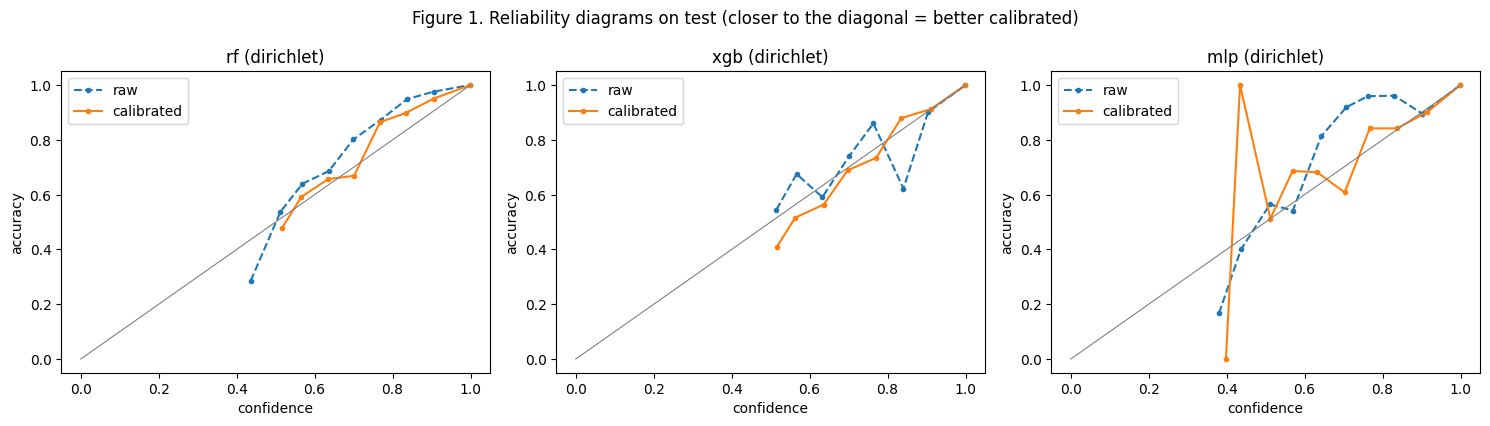

> #### Findings
> | Check | Result |
> |---|---|
> | rf | dirichlet; ECE 0.0017 → 0.0003 |
> | xgb | dirichlet; ECE 0.0006 → 0.0001 |
> | mlp | dirichlet; ECE 0.0060 → 0.0004 |
>
> **Meaning:** confidence values now match observed accuracy, so they can be used as evidence by the mechanism in Part 4.


In [47]:
y_cal, y_test = Y_ALL[IDX["cal"]], Y_ALL[IDX["test"]]
CALIB, CAL_TABLE, PROBS = {}, [], {}
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
def make(method): return ml.TemperatureScaler() if method == "temperature" else ml.DirichletCalibrator(C=1.0)
def uncal(Z):
    t = ml.TemperatureScaler(); t.T = 1.0; return t.predict_proba(Z)
for name in CLASSIFIERS:
    Zc = LOGITS[name][rows("cal")]; cv = {}
    for method in CAL_METHODS:
        cv[method] = float(np.mean([ml.nll(make(method).fit(Zc[a], y_cal[a], K).predict_proba(Zc[b]), y_cal[b])
                                    for a, b in skf.split(Zc, y_cal)]))
    best = min(cv, key=cv.get)
    CALIB[name] = make(best).fit(Zc, y_cal, K)
    joblib.dump(CALIB[name], MODEL_DIR / f"calibrator_{name}.joblib")
    PROBS[name] = CALIB[name].predict_proba(LOGITS[name]).astype("float32")
    PROBS[name] /= PROBS[name].sum(1, keepdims=True)
    Pt_raw, Pt = uncal(LOGITS[name][rows("test")]), PROBS[name][rows("test")]
    CAL_TABLE.append({"model": name, "method": best, **{f"cv_nll_{m}": round(v, 4) for m, v in cv.items()},
                      "test_NLL raw→cal": f"{ml.nll(Pt_raw, y_test):.4f} → {ml.nll(Pt, y_test):.4f}",
                      "test_ECE raw→cal": f"{ml.ece(Pt_raw, y_test):.4f} → {ml.ece(Pt, y_test):.4f}",
                      "test_classwise_ECE": round(ml.classwise_ece(Pt, y_test), 4), "test_Brier": round(ml.brier(Pt, y_test), 4),
                      "predicted_class_changed_%": round(100 * float((Pt.argmax(1) != Pt_raw.argmax(1)).mean()), 3)})
CAL_TABLE = pd.DataFrame(CAL_TABLE).set_index("model"); display(CAL_TABLE)

fig, axes = plt.subplots(1, len(CLASSIFIERS), figsize=(5 * len(CLASSIFIERS), 4.3))
for ax, name in zip(axes, CLASSIFIERS):
    for P, lab, st in [(uncal(LOGITS[name][rows("test")]), "raw", "--"), (PROBS[name][rows("test")], "calibrated", "-")]:
        xs, ys_ = ml.reliability_curve(P, y_test); ax.plot(xs, ys_, st, marker="o", ms=3, label=lab)
    ax.plot([0, 1], [0, 1], c="grey", lw=0.8); ax.set_xlabel("confidence"); ax.set_ylabel("accuracy")
    ax.set_title(f"{name} ({CAL_TABLE.loc[name, 'method']})"); ax.legend()
plt.suptitle("Figure 1. Reliability diagrams on test (closer to the diagonal = better calibrated)"); savefig("01_reliability.png")
findings([(m, f"{CAL_TABLE.loc[m, 'method']}; ECE {CAL_TABLE.loc[m, 'test_ECE raw→cal']}") for m in CLASSIFIERS],
         "confidence values now match observed accuracy, so they can be used as evidence by the mechanism in Part 4.")

## 2.8 · Anomaly detectors (benign training flows only)
An anomaly detector learns what *normal* traffic looks like and flags deviations, so it can react to attacks the classifier has never seen and to manipulated flows. Both detectors are trained **only on benign flows of the training subsample**.

Raw scores become **conformal p-values** using the benign flows of `cal`: *p* is the share of benign calibration flows that look at least as unusual. If a flow is benign, *p* is uniformly distributed, so flagging *p* < 0.05 gives a false-alarm rate of about 5% **by construction**. This puts both detectors on one scale, comparable with the classifier's calibrated confidence in Part 4.

The primary detector is chosen by AUROC on `cal`.

In [48]:
t0 = time.time()
ben = IDX["train_s"][Y_ALL[IDX["train_s"]] == BENIGN_ID]
b_fit, b_val = train_test_split(ben, test_size=0.1, random_state=SEED)
ANOM = {}
for name in ANOMALY_DETECTORS:
    t = time.time()
    if name == "iforest":
        ANOM[name] = IsolationForest(n_estimators=300, max_samples=512, random_state=SEED, n_jobs=N_JOBS).fit(X_ALL[b_fit])
        path = MODEL_DIR / "iforest.joblib"; joblib.dump(ANOM[name], path)
    else:
        ANOM[name], ae_info = ml.train_ae(X_ALL[b_fit], X_ALL[b_val], seed=SEED, device=DEVICE)
        path = MODEL_DIR / "autoencoder.pt"; torch.save({"state_dict": ANOM[name].state_dict(), "d_in": len(COLS)}, path)
    COST[name] = {"train_seconds": round(time.time() - t, 1), "training_rows": len(b_fit),
                  "model_size_mb": round(path.stat().st_size / 1e6, 2)}

def anomaly_score(name, X):
    return -ANOM["iforest"].score_samples(X) if name == "iforest" else ml.ae_score(ANOM["autoencoder"], X, DEVICE)

cal_ben = IDX["cal"][Y_ALL[IDX["cal"]] == BENIGN_ID]
A_SCORES, A_PVAL, A_REF, A_TABLE = {}, {}, {}, []
for name in ANOMALY_DETECTORS:
    A_SCORES[name] = anomaly_score(name, X_ALL[EVAL_IDX]).astype("float32")
    A_REF[name] = np.sort(anomaly_score(name, X_ALL[cal_ben])).astype("float32")
    A_PVAL[name] = ml.conformal_pvalues(A_REF[name], A_SCORES[name]).astype("float32")
    for split in ["cal", "test"]:
        r_ = rows(split); is_att = (Y_ALL[IDX[split]] != BENIGN_ID).astype(int); s = A_SCORES[name][r_]; p = A_PVAL[name][r_]
        A_TABLE.append({"detector": name, "split": split, "AUROC": round(roc_auc_score(is_att, s), 4),
                        "PR-AUC": round(average_precision_score(is_att, s), 4),
                        "attack_detection_rate": round(float((p[is_att == 1] < ANOMALY_ALPHA).mean()), 4),
                        "benign_false_alarm_rate": round(float((p[is_att == 0] < ANOMALY_ALPHA).mean()), 4)})
A_TABLE = pd.DataFrame(A_TABLE); display(A_TABLE)
PRIMARY_ANOMALY = A_TABLE[A_TABLE.split == "cal"].set_index("detector")["AUROC"].idxmax()

fam_all = mr["label_family"].to_numpy()
DET_BY_FAM = pd.DataFrame({name: pd.Series(A_PVAL[name][rows("test")] < ANOMALY_ALPHA).groupby(fam_all[IDX["test"]]).mean()
                           for name in ANOMALY_DETECTORS})
if len(IDX["unseen"]):
    un = pd.DataFrame({name: pd.Series(A_PVAL[name][rows("unseen")] < ANOMALY_ALPHA).groupby(fam_all[IDX["unseen"]]).mean()
                       for name in ANOMALY_DETECTORS})
    un.index = [f"UNSEEN: {i}" for i in un.index]; DET_BY_FAM = pd.concat([DET_BY_FAM, un])
DET_BY_FAM = DET_BY_FAM.round(3); display(DET_BY_FAM.rename_axis(f"share flagged at p < {ANOMALY_ALPHA}"))
print(f"({time.time() - t0:.0f} s)")
fa = A_TABLE[(A_TABLE.split == "test") & (A_TABLE.detector == PRIMARY_ANOMALY)].iloc[0]
findings([("Primary detector (best cal AUROC)", PRIMARY_ANOMALY),
          ("Test AUROC / PR-AUC", f"{fa['AUROC']} / {fa['PR-AUC']}"),
          (f"Benign false-alarm rate at p < {ANOMALY_ALPHA} (target ≈ {ANOMALY_ALPHA})", f"{fa['benign_false_alarm_rate']}"),
          ("Unseen-family flows flagged", ", ".join(f"{i[8:]}: {v:.0%}" for i, v in DET_BY_FAM[PRIMARY_ANOMALY].items() if str(i).startswith("UNSEEN")) or "n/a")],
         "a false-alarm rate close to the chosen level confirms the p-values are valid. Families the detector rarely flags "
         "are where it adds little on its own; its value for RQ2 is as an independent second opinion.")

,detector,split,AUROC,PR-AUC,attack_detection_rate,benign_false_alarm_rate
0,iforest,cal,0.8939,0.4310,0.0899,0.0500
1,iforest,test,0.8946,0.4327,0.0883,0.0495
2,autoencoder,cal,0.9760,0.8644,0.8811,0.0500
3,autoencoder,test,0.9760,0.8630,0.8831,0.0511


,iforest,autoencoder
share flagged at p < 0.05,,
Benign,0.050,0.051
Bot,0.367,0.053
BruteForce,0.000,0.223
DDoS,0.132,0.919
DoS,0.061,0.908
PortScan,0.268,0.659
WebAttack,0.007,0.047
UNSEEN: Heartbleed,1.000,1.000
UNSEEN: Infiltration,0.806,0.917


(37 s)


> #### Findings
> | Check | Result |
> |---|---|
> | Primary detector (best cal AUROC) | autoencoder |
> | Test AUROC / PR-AUC | 0.976 / 0.863 |
> | Benign false-alarm rate at p < 0.05 (target ≈ 0.05) | 0.0511 |
> | Unseen-family flows flagged | Heartbleed: 100%, Infiltration: 92% |
>
> **Meaning:** a false-alarm rate close to the chosen level confirms the p-values are valid. Families the detector rarely flags are where it adds little on its own; its value for RQ2 is as an independent second opinion.


## 2.9 · Clean evaluation (test, reported once)
The "before attack" reference for RQ1 and the individual-model baseline for RQ3. Reported on the **natural-mix `test` set** (real class proportions) and on **`test-lite`** (the balanced subset Parts 3–5 use), so later `test-lite` results can be compared directly. 95% confidence intervals come from a bootstrap over flows.

,split,model,macro_F1,CI95,macro_recall,benign_FPR,missed_attacks_%,macro_PR_AUC
0,test,rf,0.9461,"[0.9392, 0.9540]",0.9237,0.00031,0.379,0.9779
1,test,xgb,0.9559,"[0.9496, 0.9613]",0.9488,0.00042,0.202,0.9788
2,test,mlp,0.9355,"[0.9291, 0.9427]",0.9177,0.00141,1.029,0.9565
3,test_lite,rf,0.9223,"[0.9121, 0.9334]",0.9242,0.00000,8.357,0.9997
4,test_lite,xgb,0.9501,"[0.9414, 0.9592]",0.9498,0.00000,5.440,0.9992
5,test_lite,mlp,0.9184,"[0.9061, 0.9281]",0.9175,0.00000,8.749,0.9965


,rf,xgb,mlp
F1 on test,,,
Benign,0.9995,0.9996,0.9984
Bot,0.6682,0.7390,0.6612
BruteForce,0.9973,0.9992,0.9825
DDoS,0.9995,0.9997,0.9985
DoS,0.9976,0.9984,0.9885
PortScan,0.9769,0.9717,0.9728
WebAttack,0.9836,0.9836,0.9466


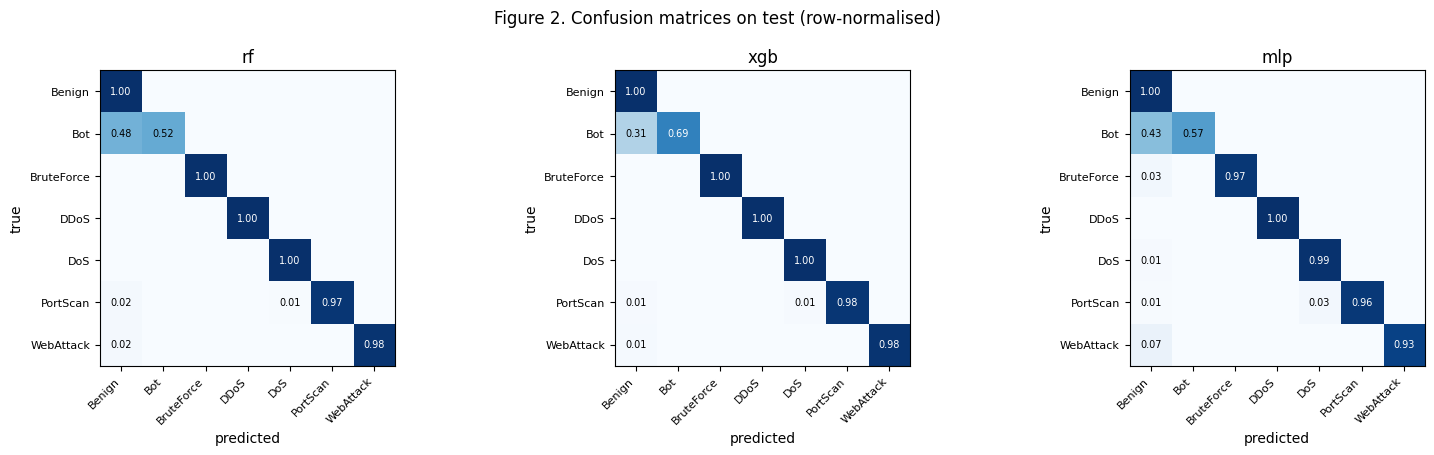

> #### Findings
> | Check | Result |
> |---|---|
> | rf macro-F1 (test) | 0.9461 [0.9392, 0.9540] |
> | xgb macro-F1 (test) | 0.9559 [0.9496, 0.9613] |
> | mlp macro-F1 (test) | 0.9355 [0.9291, 0.9427] |
> | Best clean model | xgb |
> | Weakest families (lowest F1 across models) | Bot 0.661, WebAttack 0.947 |
>
> **Meaning:** these are the clean reference scores: RQ1 measures how far they fall under attack, RQ3 compares the mechanism against them.


In [49]:
def boot_ci(y, p, n=N_BOOT, seed=SEED):
    r = np.random.default_rng(seed)
    vals = [macro_f1(y[b], p[b], K) for b in (r.integers(0, len(y), len(y)) for _ in range(n))]
    return np.percentile(vals, [2.5, 97.5])

EVAL, PER_CLASS = [], {}
for split in ["test", "test_lite"]:
    r_, y_ = rows(split), Y_ALL[IDX[split]]; ben = y_ == BENIGN_ID; oh = np.eye(K)[y_]
    for name in CLASSIFIERS:
        P = PROBS[name][r_]; pr = P.argmax(1); lo, hi = boot_ci(y_, pr)
        EVAL.append({"split": split, "model": name, "macro_F1": round(macro_f1(y_, pr, K), 4), "CI95": f"[{lo:.4f}, {hi:.4f}]",
                     "macro_recall": round(float(np.mean([(pr[y_ == k] == k).mean() for k in range(K) if (y_ == k).any()])), 4),
                     "benign_FPR": round(float((pr[ben] != BENIGN_ID).mean()), 5),
                     "missed_attacks_%": round(100 * float((pr[~ben] == BENIGN_ID).mean()), 3),
                     "macro_PR_AUC": round(float(np.mean([average_precision_score(oh[:, k], P[:, k]) for k in range(K) if oh[:, k].any()])), 4)})
        if split == "test":
            PER_CLASS[name] = f1_score(y_, pr, average=None, labels=list(range(K)))
EVAL = pd.DataFrame(EVAL); display(EVAL)
PER_CLASS = pd.DataFrame(PER_CLASS, index=CLASSES).round(4); display(PER_CLASS.rename_axis("F1 on test"))

fig, axes = plt.subplots(1, len(CLASSIFIERS), figsize=(5.2 * len(CLASSIFIERS), 4.6))
for ax, name in zip(axes, CLASSIFIERS):
    cm = confusion_matrix(Y_ALL[IDX["test"]], PROBS[name][rows("test")].argmax(1), labels=list(range(K)), normalize="true")
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    for i in range(K):
        for j in range(K):
            if cm[i, j] >= 0.005:
                ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=7, color="white" if cm[i, j] > 0.6 else "black")
    ax.set_xticks(range(K)); ax.set_xticklabels(CLASSES, rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(K)); ax.set_yticklabels(CLASSES, fontsize=8); ax.set_title(name); ax.set_xlabel("predicted"); ax.set_ylabel("true")
plt.suptitle("Figure 2. Confusion matrices on test (row-normalised)"); savefig("02_confusion.png")
ET = EVAL[EVAL.split == "test"].set_index("model")
weak = PER_CLASS.min(axis=1).sort_values().head(2)
findings([(f"{m} macro-F1 (test)", f"{ET.loc[m, 'macro_F1']} {ET.loc[m, 'CI95']}") for m in CLASSIFIERS] +
         [("Best clean model", ET["macro_F1"].idxmax()),
          ("Weakest families (lowest F1 across models)", ", ".join(f"{k} {v:.3f}" for k, v in weak.items()))],
         "these are the clean reference scores: RQ1 measures how far they fall under attack, RQ3 compares the mechanism against them.")

## 2.10 · Clean SHAP baseline
SHAP values (Lundberg & Lee, 2017) give each feature's contribution to one prediction. They are computed **before any attack** on:
* `test-lite` (and therefore `agent-eval`): the "before" ranking for RQ1 and the evidence passed to the agents in Part 5;
* `thr-lite`: used to tune the mechanism in Part 4;
* `unseen` flows;
* the **prototype set** of training flows: their average explanation per family defines a "typical" explanation; Part 4 measures how far a flow's explanation is from its predicted family's prototype.

Explainers: exact **TreeSHAP** for Random Forest and XGBoost, **expected gradients** (GradientExplainer) for the MLP. The explanation of the **predicted class** is stored, plus all classes. Time per flow is recorded for RQ4.

rf: 5,970 flows in 762 s (127.7 ms/flow)
xgb: 5,970 flows in 2 s (0.3 ms/flow)
mlp: 5,970 flows in 604 s (101.2 ms/flow)


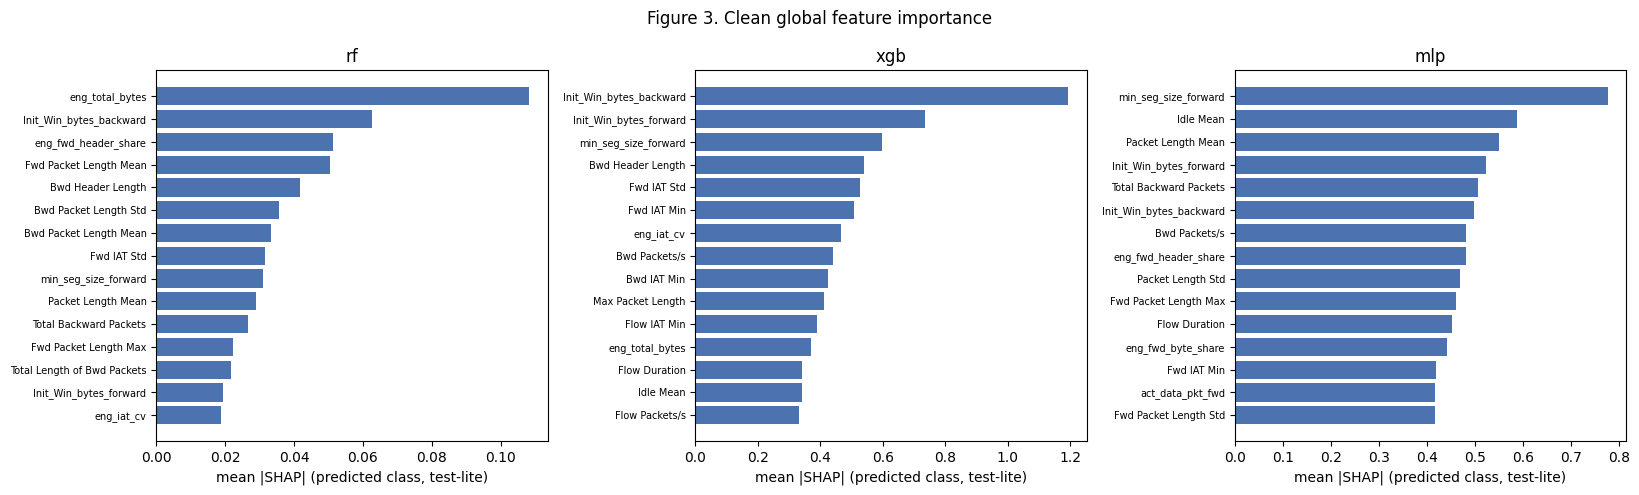

,rf,xgb,mlp
share of |SHAP|,,,
engineered,0.279,0.154,0.192
size_fwd,0.116,0.042,0.098
size_bwd,0.109,0.061,0.076
header,0.096,0.106,0.086
tcp_window,0.095,0.149,0.060
size_flow,0.059,0.058,0.088
timing_fwd,0.059,0.101,0.057
timing_flow,0.040,0.070,0.056
rate,0.037,0.084,0.064


,pair,global_rank_kendall_tau,per_flow_top5_jaccard
0,rf vs xgb,0.531,0.172
1,rf vs mlp,0.565,0.138
2,xgb vs mlp,0.502,0.145


> #### Findings
> | Check | Result |
> |---|---|
> | rf top-3 features | eng_total_bytes, Init_Win_bytes_backward, eng_fwd_header_share |
> | xgb top-3 features | Init_Win_bytes_backward, Init_Win_bytes_forward, min_seg_size_forward |
> | mlp top-3 features | min_seg_size_forward, Idle Mean, Packet Length Mean |
> | SHAP time per flow (ms) | rf 127.7, xgb 0.3, mlp 101.2 |
> | Cross-model agreement (Kendall τ of global ranking) | rf vs xgb: 0.531, rf vs mlp: 0.565, xgb vs mlp: 0.502 |
>
> **Meaning:** this is the clean reference for RQ1's SHAP-ranking stability. Where models disagree on which features matter, each relies on different evidence, so explanation stability is measured per model.


In [50]:
SHAP_KEYS = ["test_lite", "thr_lite", "unseen", "proto"]
S_IDX = np.unique(np.concatenate([IDX[k] for k in SHAP_KEYS]))
XS = X_ALL[S_IDX]
bg_idx = np.concatenate([rng.choice(np.flatnonzero(M["train_s"] & (Y_ALL == k)), size=max(1, SHAP_BACKGROUND // K), replace=False)
                         for k in range(K)])

def to_nfk(sv, n, f):
    a = np.stack(sv, axis=-1) if isinstance(sv, list) else np.asarray(sv)
    if a.ndim == 3 and a.shape[0] == n and a.shape[1] == f: return a
    if a.ndim == 3 and a.shape[1] == n and a.shape[2] == f: return np.transpose(a, (1, 2, 0))
    raise ValueError(f"unexpected SHAP shape {a.shape}")

SHAP_ALL, SHAP_PRED, SHAP_TIME = {}, {}, {}
for name in CLASSIFIERS:
    t = time.time()
    if name in ("rf", "xgb"):
        sv = shap.TreeExplainer(MODELS[name]).shap_values(XS, check_additivity=False)
    else:
        net = MODELS["mlp"].eval()                       # expected gradients; model and data on the same device
        gx = shap.GradientExplainer(net, torch.as_tensor(X_ALL[bg_idx]).to(DEVICE), batch_size=500)
        sv = gx.shap_values(torch.as_tensor(XS).to(DEVICE), nsamples=50, rseed=SEED)
    SHAP_TIME[name] = (time.time() - t) / len(XS)
    a = to_nfk(sv, len(XS), len(COLS)).astype("float32")
    pred = raw_logits(name, XS).argmax(1)
    SHAP_ALL[name] = a; SHAP_PRED[name] = a[np.arange(len(XS)), :, pred]
    print(f"{name}: {len(XS):,} flows in {time.time() - t:.0f} s ({1e3 * SHAP_TIME[name]:.1f} ms/flow)")

SP = pd.Series(np.arange(len(S_IDX)), index=S_IDX)
tl = SP.loc[IDX["test_lite"]].to_numpy()
GLOBAL = pd.DataFrame({name: np.abs(SHAP_PRED[name][tl]).mean(0) for name in CLASSIFIERS}, index=COLS)
fig, axes = plt.subplots(1, len(CLASSIFIERS), figsize=(5.5 * len(CLASSIFIERS), 5))
for ax, name in zip(axes, CLASSIFIERS):
    top = GLOBAL[name].sort_values().tail(15); ax.barh(top.index, top.values, color="#4C72B0")
    ax.set_title(name); ax.set_xlabel("mean |SHAP| (predicted class, test-lite)"); ax.tick_params(axis="y", labelsize=7)
plt.suptitle("Figure 3. Clean global feature importance"); savefig("03_shap_global.png")

grp_of = {f: g for g, fl in FEATURE_GROUPS.items() for f in fl}
GROUP_IMP = GLOBAL.groupby(lambda f: grp_of.get(f, "missing_indicator" if f.endswith("__missing") else "other")).sum()
GROUP_IMP = (GROUP_IMP / GROUP_IMP.sum()).round(3).sort_values(CLASSIFIERS[0], ascending=False)
display(GROUP_IMP.rename_axis("share of |SHAP|"))

AGREE = []
for i, a in enumerate(CLASSIFIERS):
    for b in CLASSIFIERS[i + 1:]:
        tau = kendalltau(GLOBAL[a], GLOBAL[b]).statistic
        top_a = np.argsort(-np.abs(SHAP_PRED[a][tl]), 1)[:, :5]; top_b = np.argsort(-np.abs(SHAP_PRED[b][tl]), 1)[:, :5]
        jac = np.mean([len(set(x) & set(y)) / len(set(x) | set(y)) for x, y in zip(top_a, top_b)])
        AGREE.append({"pair": f"{a} vs {b}", "global_rank_kendall_tau": round(float(tau), 3), "per_flow_top5_jaccard": round(float(jac), 3)})
AGREE = pd.DataFrame(AGREE); display(AGREE)

pr_rows = SP.loc[IDX["proto"]].to_numpy(); fam_p = Y_ALL[IDX["proto"]]
PROTOTYPES = {name: np.stack([SHAP_PRED[name][pr_rows][fam_p == k].mean(0) for k in range(K)]) for name in CLASSIFIERS}
findings([(f"{m} top-3 features", ", ".join(GLOBAL[m].sort_values(ascending=False).index[:3])) for m in CLASSIFIERS] +
         [("SHAP time per flow (ms)", ", ".join(f"{m} {1e3 * SHAP_TIME[m]:.1f}" for m in CLASSIFIERS)),
          ("Cross-model agreement (Kendall τ of global ranking)", ", ".join(f"{r.pair}: {r.global_rank_kendall_tau}" for r in AGREE.itertuples()))],
         "this is the clean reference for RQ1's SHAP-ranking stability. Where models disagree on which features matter, "
         "each relies on different evidence, so explanation stability is measured per model.")

## 2.11 · Latency and computational cost (RQ4 inputs)
Per-flow latency (single flow; median and 95th percentile) and batched throughput, measured the same way for every component. Part 5 adds attack, mechanism and LLM-agent costs to this table.

In [51]:
Xbench = X_ALL[IDX["test"]]
FN = {"rf": lambda X: MODELS["rf"].predict_proba(X), "xgb": lambda X: MODELS["xgb"].predict_proba(X),
      "mlp": lambda X: ml.torch_logits(MODELS["mlp"], X, DEVICE),
      "iforest": lambda X: ANOM["iforest"].score_samples(X), "autoencoder": lambda X: ml.ae_score(ANOM["autoencoder"], X, DEVICE)}
for name in CLASSIFIERS + ANOMALY_DETECTORS:
    fn = FN[name]
    COST[name].update({k: round(v, 3) for k, v in ml.time_per_flow(fn, Xbench, n_single=200, batch=10_000, seed=SEED).items()})
for name in CLASSIFIERS:
    COST[name]["shap_ms_per_flow"] = round(1e3 * SHAP_TIME[name], 2)
COST_TABLE = pd.DataFrame(COST).T; COST_TABLE["device"] = DEVICE; COST_TABLE["peak_ram_gb_process"] = round(peak_ram_gb(), 2)
display(COST_TABLE)
lat = COST_TABLE.loc[CLASSIFIERS, "latency_ms_p50"].astype(float)
findings([("Fastest classifier (p50 latency)", f"{lat.idxmin()} ({lat.min():.2f} ms)"),
          ("SHAP cost per flow", ", ".join(f"{m} {COST_TABLE.loc[m, 'shap_ms_per_flow']} ms" for m in CLASSIFIERS))],
         "explanation is usually far more expensive than prediction. Because the mechanism needs explanation stability, "
         "this is one of the central trade-offs examined in RQ4.")

,train_seconds,model_size_mb,training_rows,imbalance,latency_ms_p50,latency_ms_p95,throughput_flows_per_s,shap_ms_per_flow,device,peak_ram_gb_process
rf,144.7,8.54,321277,class_weight,45.495,55.741,113850.116,127.68,cuda,10.17
xgb,18.3,7.77,321277,class_weight,8.0,10.93,525370.841,0.32,cuda,10.17
mlp,7.0,0.81,328099,smote,0.576,0.683,4066315.094,101.19,cuda,10.17
iforest,1.4,6.27,180000.0,NaN,18.242,22.856,47555.592,NaN,cuda,10.17
autoencoder,16.2,0.06,180000.0,NaN,0.504,0.607,6372105.471,NaN,cuda,10.17


> #### Findings
> | Check | Result |
> |---|---|
> | Fastest classifier (p50 latency) | mlp (0.58 ms) |
> | SHAP cost per flow | rf 127.68 ms, xgb 0.32 ms, mlp 101.19 ms |
>
> **Meaning:** explanation is usually far more expensive than prediction. Because the mechanism needs explanation stability, this is one of the central trade-offs examined in RQ4.


## 2.12 · Final checks

In [52]:
held_out = np.concatenate([IDX["cal"], IDX["thr"], IDX["test"], IDX["unseen"]])
checks = {
    "tuning / model choices used only training flows": not np.isin(np.concatenate([i_fit, i_val]), held_out).any(),
    "anomaly detectors trained on benign training flows only": bool((Y_ALL[b_fit] == BENIGN_ID).all() and M["train_s"][b_fit].all()),
    "calibrated probabilities sum to 1": all(np.allclose(PROBS[m].sum(1), 1, atol=1e-4) for m in CLASSIFIERS),
    "anomaly p-values in (0, 1]": all(((A_PVAL[a] > 0) & (A_PVAL[a] <= 1)).all() for a in ANOMALY_DETECTORS),
    "benign false-alarm rate within 2 points of alpha": bool(abs(fa["benign_false_alarm_rate"] - ANOMALY_ALPHA) <= 0.02),
    "SHAP computed for every required flow": all(SHAP_PRED[m].shape[0] == len(S_IDX) for m in CLASSIFIERS),
    "no NaN in SHAP values": all(np.isfinite(SHAP_ALL[m]).all() for m in CLASSIFIERS),
}
display(pd.DataFrame([(k, "✔ pass" if v else "✘ FAIL") for k, v in checks.items()], columns=["check", "result"]))
assert all(checks.values()), "A final check failed."
findings([("Checks passed", f"{sum(checks.values())} of {len(checks)}")])

,check,result
0,tuning / model choices used only training flows,✔ pass
1,anomaly detectors trained on benign training f...,✔ pass
2,calibrated probabilities sum to 1,✔ pass
3,"anomaly p-values in (0, 1]",✔ pass
4,benign false-alarm rate within 2 points of alpha,✔ pass
5,SHAP computed for every required flow,✔ pass
6,no NaN in SHAP values,✔ pass


> #### Findings
> | Check | Result |
> |---|---|
> | Checks passed | 7 of 7 |


## 2.13 · Saved outputs

In [53]:
pred = pd.DataFrame({"row_id": EVAL_IDX, "label_id": Y_ALL[EVAL_IDX], "Label": LAB_ALL[EVAL_IDX],
                     "split": mr["split"].to_numpy()[EVAL_IDX], "in_test_lite": M["test_lite"][EVAL_IDX],
                     "in_thr_lite": M["thr_lite"][EVAL_IDX], "in_agent_eval": M["agent"][EVAL_IDX], "in_proto": M["proto"][EVAL_IDX]})
for name in CLASSIFIERS:
    for k, c in enumerate(CLASSES):
        pred[f"{name}_p_{c}"] = PROBS[name][:, k]
    pred[f"{name}_pred"] = PROBS[name].argmax(1).astype("int8"); pred[f"{name}_conf"] = PROBS[name].max(1)
for a in ANOMALY_DETECTORS:
    pred[f"{a}_score"] = A_SCORES[a]; pred[f"{a}_pvalue"] = A_PVAL[a]
pred.to_parquet(OUT_DIR / "predictions_clean.parquet", compression="zstd", index=False)
np.savez_compressed(OUT_DIR / "shap_clean.npz", row_id=S_IDX, columns=np.array(COLS), background_rows=bg_idx,
                    **{f"{m}_pred": SHAP_PRED[m] for m in CLASSIFIERS}, **{f"{m}_all": SHAP_ALL[m] for m in CLASSIFIERS},
                    **{f"{m}_prototypes": PROTOTYPES[m] for m in CLASSIFIERS})
np.savez_compressed(OUT_DIR / "anomaly_reference.npz", **{f"{a}_cal_benign_scores": A_REF[a] for a in ANOMALY_DETECTORS})
CONFIG = {"classifiers": CLASSIFIERS, "anomaly_detectors": ANOMALY_DETECTORS, "primary_anomaly": PRIMARY_ANOMALY,
          "best_params": BEST, "imbalance": STRATEGY, "calibration": CAL_TABLE["method"].to_dict(),
          "anomaly_alpha": ANOMALY_ALPHA, "port_ablation": PORT_ABL, "classes": CLASSES, "model_cols": COLS,
          "nb1_dir": str(NB1), "environment": ENV}
json.dump(CONFIG, open(OUT_DIR / "detectors_config.json", "w"), indent=2, default=to_builtin)
TUNING.to_csv(OUT_DIR / "tuning.csv", index=False); IMB.to_csv(OUT_DIR / "imbalance_choice.csv")
CAL_TABLE.to_csv(OUT_DIR / "calibration.csv"); A_TABLE.to_csv(OUT_DIR / "anomaly_eval.csv", index=False)
DET_BY_FAM.to_csv(OUT_DIR / "anomaly_detection_by_family.csv"); EVAL.to_csv(OUT_DIR / "clean_eval.csv", index=False)
PER_CLASS.to_csv(OUT_DIR / "clean_f1_per_family.csv"); GLOBAL.to_csv(OUT_DIR / "shap_global_importance.csv")
GROUP_IMP.to_csv(OUT_DIR / "shap_group_importance.csv"); AGREE.to_csv(OUT_DIR / "shap_cross_model_agreement.csv", index=False)
COST_TABLE.to_csv(OUT_DIR / "cost_profile.csv")
display(pd.DataFrame([(str(p.relative_to(OUT_DIR)), round(p.stat().st_size / 1e6, 2)) for p in sorted(OUT_DIR.rglob("*"))
                      if p.is_file() and "__pycache__" not in str(p)], columns=["file", "size_mb"]))

,file,size_mb
0,anomaly_detection_by_family.csv,0.00
1,anomaly_eval.csv,0.00
2,anomaly_reference.npz,0.78
3,calibration.csv,0.00
4,clean_eval.csv,0.00
5,clean_f1_per_family.csv,0.00
6,cost_profile.csv,0.00
7,detectors_config.json,0.00
8,figures/01_reliability.png,0.15
9,figures/02_confusion.png,0.11


> #### Saved files
> | File | Use in later parts |
> |---|---|
> | `models/` (`rf.joblib`, `xgb.json`, `mlp.pt`, `iforest.joblib`, `autoencoder.pt`, `calibrator_*.joblib`) | attacked in Part 3; indicators in Part 4; agents' tools in Part 5 |
> | `models_lib.py` | load models, calibrate, conformal p-values, timing |
> | `predictions_clean.parquet` | calibrated probabilities, predictions, confidence, anomaly scores and p-values per flow |
> | `shap_clean.npz` | clean SHAP (predicted class and all classes), class prototypes, background rows |
> | `anomaly_reference.npz` | benign calibration scores, to compute p-values for attacked flows |
> | `cost_profile.csv` | RQ4 cost table (extended in Part 5) |

<a id="overfit"></a>
## 2.14 · Overfitting analysis
A model overfits when it learns the training data — including its noise — so well that it performs clearly worse on data it has not seen. Three diagnostics test this for the three classifiers:

| Diagnostic | What would indicate overfitting |
|---|---|
| **(a) Train vs held-out gap** — macro-F1 on the training subsample, on `cal`, on `test`, and on `test` *resampled to the training class mix* | a large drop from training to held-out data **that remains** when both have the same class mix. (A drop that disappears after resampling is caused by the real class imbalance of the test set, not by overfitting.) |
| **(b) Learning curves** — XGBoost and Random Forest retrained on 5–100 % of the training subsample with the tuned hyper-parameters | training score far above the held-out score, with the gap not closing as data grows |
| **(c) Boosting curve** — XGBoost multi-class log-loss on training and held-out (`cal`) data after every boosting round | held-out loss rising again while training loss keeps falling |

Only training and `cal` flows are used to *fit* anything here; the test set is only scored. This section reloads the saved models and data, so it can be run on its own (≈ 5–8 minutes on GPU).

In [54]:
# Self-contained: reloads Part 1 data and Part 2 models from the saved files
%reset -f
import os, sys, json, time, warnings, gc
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib, xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")
INPUT_ROOT = Path(os.environ.get("IDS_INPUT_ROOT", "/kaggle/input")); WORK_ROOT = Path(os.environ.get("IDS_WORK_ROOT", "/kaggle/working"))
SEED = 42; rng = np.random.default_rng(SEED)
FRACTIONS = [0.05, 0.10, 0.25, 0.50, 1.00]       # learning-curve training sizes
RF_TREES_LC = 100                                # trees per learning-curve forest (final model: 200)
EVAL_ROWS = 200_000                              # rows scored per split (speed); test resampling uses all test rows

def find_dir(marker, local):
    hits = sorted((WORK_ROOT / local).glob(marker)) + sorted(INPUT_ROOT.rglob(marker))
    assert hits, f"{marker} not found: run Parts 1–2 first or attach their outputs"; return hits[0].parent
NB1 = find_dir("feature_sets.json", "nb1_data_foundation"); NB2 = find_dir("detectors_config.json", "nb2_detectors")
sys.path.insert(0, str(NB2)); import models_lib as ml
CFG = json.load(open(NB2 / "detectors_config.json")); CLASSES, COLS = CFG["classes"], CFG["model_cols"]; K = len(CLASSES)
BEST, STRATEGY = CFG["best_params"], CFG["imbalance"]
CW = json.load(open(NB1 / "class_weights.json")); CW_VEC = np.array([CW["by_label_id"][str(i)] for i in range(K)], dtype="float32")
FIG = WORK_ROOT / "nb2_detectors" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
try:
    import torch; DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except ImportError:
    torch, DEVICE = None, "cpu"

def macro_f1(y, p):
    y, p = np.asarray(y, int), np.asarray(p, int)
    cm = np.bincount(y * K + p, minlength=K * K).reshape(K, K); tp = np.diag(cm)
    pr = tp / np.maximum(cm.sum(0), 1); rc = tp / np.maximum(cm.sum(1), 1)
    f = np.where(pr + rc > 0, 2 * pr * rc / np.maximum(pr + rc, 1e-12), 0); return float(f[cm.sum(1) > 0].mean())
def per_class_f1(y, p):
    y, p = np.asarray(y, int), np.asarray(p, int)
    out = []
    for k in range(K):
        tp = ((y == k) & (p == k)).sum(); fp = ((y != k) & (p == k)).sum(); fn = ((y == k) & (p != k)).sum()
        out.append(2 * tp / (2 * tp + fp + fn) if (y == k).any() else np.nan)
    return np.array(out)

t0 = time.time()
mr = pd.read_parquet(NB1 / "cicids2017_model_ready.parquet", columns=COLS + ["label_id", "split", "in_train_sample"])
X = mr[COLS].to_numpy("float32"); Y = mr["label_id"].to_numpy().astype(int)
IDX = {"train": np.flatnonzero(mr["in_train_sample"].to_numpy()), "cal": np.flatnonzero((mr["split"].astype(str) == "cal").to_numpy()),
       "test": np.flatnonzero((mr["split"].astype(str) == "test").to_numpy())}
del mr; gc.collect()

MODELS = {}
MODELS["rf"] = joblib.load(NB2 / "models" / "rf.joblib")
MODELS["xgb"] = xgb.XGBClassifier(); MODELS["xgb"].load_model(NB2 / "models" / "xgb.json")
try: MODELS["xgb"].set_params(device=DEVICE)
except Exception: pass
if torch is not None and (NB2 / "models" / "mlp.pt").exists():
    ck = torch.load(NB2 / "models" / "mlp.pt", map_location=DEVICE)
    net = ml.MLP(ck["d_in"], ck["n_out"], tuple(ck["hidden"]), ck["dropout"]); net.load_state_dict(ck["state_dict"])
    MODELS["mlp"] = net.to(DEVICE).eval()
def predict(name, Xb):
    if name == "mlp": return ml.torch_logits(MODELS["mlp"], Xb, DEVICE).argmax(1)
    return MODELS[name].predict_proba(Xb).argmax(1)
print(f"loaded {len(X):,} flows and {len(MODELS)} models in {time.time() - t0:.0f} s")


loaded 2,233,302 flows and 3 models in 3 s


In [55]:
# (a) Train vs held-out gap, and the class-mix control
def sub(idx, n): return idx if len(idx) <= n else np.sort(rng.choice(idx, n, replace=False))
train_rows, cal_rows, test_rows = sub(IDX["train"], EVAL_ROWS), sub(IDX["cal"], EVAL_ROWS), IDX["test"]
# test resampled to the class mix of the training subsample (with replacement only where a class is too small)
mix = np.bincount(Y[IDX["train"]], minlength=K) / len(IDX["train"]); n_mix = min(EVAL_ROWS, len(test_rows))
test_mix = np.concatenate([rng.choice(test_rows[Y[test_rows] == k], int(round(mix[k] * n_mix)),
                                      replace=int(round(mix[k] * n_mix)) > (Y[test_rows] == k).sum())
                           for k in range(K) if (Y[test_rows] == k).any() and mix[k] > 0])
GAP, PCF = [], {}
for name in MODELS:
    t = time.time(); s = {}
    for lab, rows in [("train subsample", train_rows), ("cal (held-out)", cal_rows), ("test (held-out)", test_rows),
                      ("test, training class mix", test_mix)]:
        p = predict(name, X[rows]); s[lab] = macro_f1(Y[rows], p)
        if lab in ("train subsample", "test (held-out)"): PCF[(name, lab)] = per_class_f1(Y[rows], p)
    GAP.append({"model": name, **s, "gap: train − test": s["train subsample"] - s["test (held-out)"],
                "gap: train − test (same class mix)": s["train subsample"] - s["test, training class mix"]})
    print(f"  {name}: {time.time() - t:.0f} s")
GAP = pd.DataFrame(GAP).set_index("model")
display(GAP.style.format("{:.4f}").background_gradient(subset=["gap: train − test (same class mix)"], cmap="Reds", vmin=0, vmax=0.1)
        .set_caption("Table 2.14a · Macro-F1 on training vs held-out data"))
PC = pd.DataFrame({f"{n} · {'train' if 'train' in l else 'test'}": v for (n, l), v in PCF.items()}, index=CLASSES)
for n in MODELS: PC[f"{n} · gap"] = PC[f"{n} · train"] - PC[f"{n} · test"]
display(PC.style.format("{:.3f}").background_gradient(subset=[c for c in PC.columns if c.endswith("gap")], cmap="Reds", vmin=0, vmax=0.2)
        .set_caption("Table 2.14b · Per-family F1 on training vs test (largest gaps show where generalisation is weakest)"))


  rf: 5 s
  xgb: 3 s
  mlp: 1 s


,train subsample,cal (held-out),test (held-out),"test, training class mix",gap: train − test,gap: train − test (same class mix)
model,,,,,,
rf,0.9928,0.9495,0.9527,0.9828,0.0401,0.0100
xgb,0.9892,0.9378,0.9404,0.9829,0.0488,0.0063
mlp,0.9628,0.9213,0.9242,0.9662,0.0386,-0.0034


,rf · train,rf · test,xgb · train,xgb · test,mlp · train,mlp · test,rf · gap,xgb · gap,mlp · gap
Benign,1.000,0.999,0.999,0.999,0.996,0.998,0.000,0.000,-0.001
Bot,0.956,0.720,0.927,0.650,0.856,0.697,0.235,0.277,0.159
BruteForce,0.999,0.996,1.000,0.999,0.982,0.972,0.004,0.001,0.010
DDoS,1.000,1.000,1.000,1.000,0.999,0.998,0.000,0.000,0.002
DoS,0.999,0.997,0.999,0.998,0.993,0.984,0.002,0.001,0.010
PortScan,0.997,0.972,0.999,0.959,0.971,0.955,0.025,0.040,0.016
WebAttack,0.999,0.985,0.999,0.977,0.942,0.868,0.014,0.022,0.075


  xgb 5%: 16,064 rows, 4 s
  xgb 10%: 32,128 rows, 4 s
  xgb 25%: 80,320 rows, 7 s
  xgb 50%: 160,640 rows, 11 s
  xgb 100%: 321,277 rows, 19 s
  rf 5%: 16,064 rows, 3 s
  rf 10%: 32,128 rows, 6 s
  rf 25%: 80,320 rows, 15 s
  rf 50%: 160,640 rows, 32 s
  rf 100%: 321,277 rows, 72 s


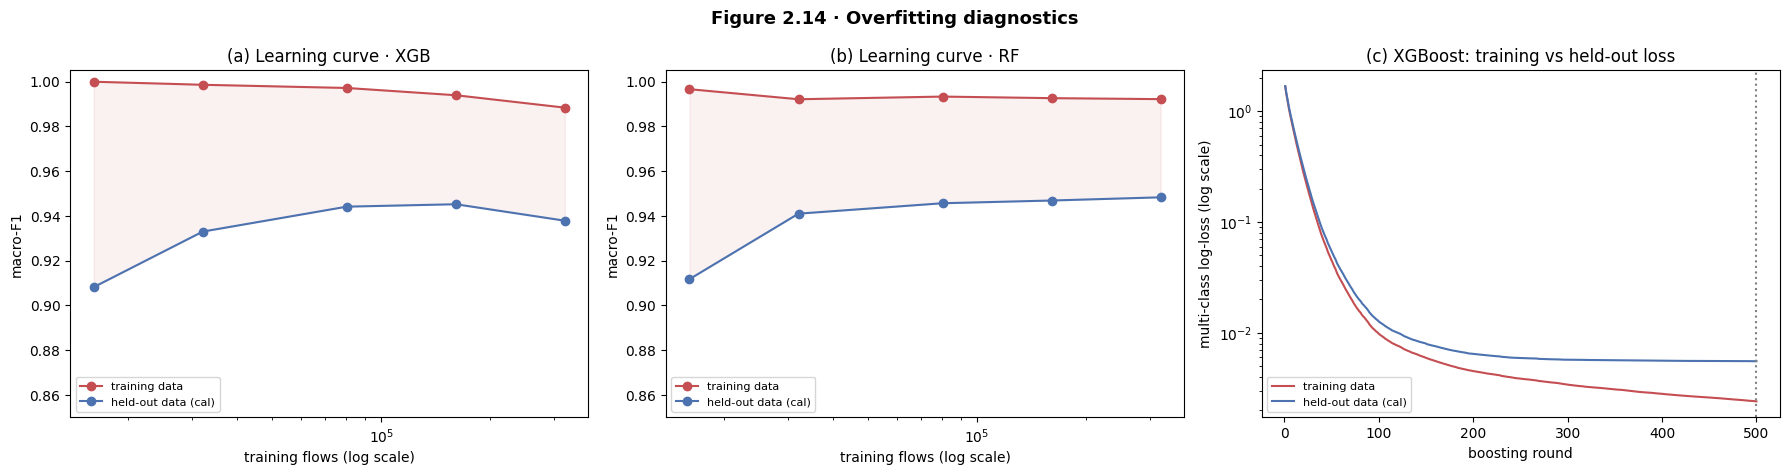

model,fraction,training rows,train macro-F1,held-out (cal) macro-F1,gap
xgb,5%,"16,064",0.9999,0.9081,0.0918
xgb,10%,"32,128",0.9985,0.9329,0.0656
xgb,25%,"80,320",0.9971,0.9441,0.0530
xgb,50%,"160,640",0.9939,0.9451,0.0487
xgb,100%,"321,277",0.9883,0.9378,0.0505
rf,5%,"16,064",0.9966,0.9117,0.0849
rf,10%,"32,128",0.9921,0.9409,0.0511
rf,25%,"80,320",0.9933,0.9456,0.0477
rf,50%,"160,640",0.9926,0.9468,0.0458
rf,100%,"321,277",0.9921,0.9482,0.0439


In [56]:
# (b) Learning curves (XGBoost, Random Forest) and (c) XGBoost boosting curve
def fit(name, rows):
    w = CW_VEC[Y[rows]] if STRATEGY.get(name, "class_weight") == "class_weight" else None
    p = BEST[name]
    if name == "rf":
        return RandomForestClassifier(n_estimators=RF_TREES_LC, max_depth=p["max_depth"], min_samples_leaf=p["min_samples_leaf"],
                                      max_features=p["max_features"], n_jobs=-1, random_state=SEED).fit(X[rows], Y[rows], sample_weight=w)
    m = xgb.XGBClassifier(objective="multi:softprob", num_class=K, tree_method="hist", device=DEVICE, n_estimators=p["n_estimators"],
                          max_depth=p["max_depth"], learning_rate=p["learning_rate"], subsample=p["subsample"],
                          colsample_bytree=p["colsample_bytree"], min_child_weight=p["min_child_weight"], reg_lambda=p["reg_lambda"],
                          random_state=SEED, n_jobs=-1, eval_metric="mlogloss")
    return m.fit(X[rows], Y[rows], sample_weight=w, verbose=False)

def stratified_fraction(idx, frac):
    out = [rng.choice(idx[Y[idx] == k], max(2, int(round(frac * (Y[idx] == k).sum()))), replace=False)
           for k in range(K) if (Y[idx] == k).sum() >= 2]
    return np.sort(np.concatenate(out))

LC = []
for name in ["xgb", "rf"]:
    for f in FRACTIONS:
        t = time.time(); rows = stratified_fraction(IDX["train"], f); m = fit(name, rows)
        tr_eval = rows if len(rows) <= EVAL_ROWS else np.sort(rng.choice(rows, EVAL_ROWS, replace=False))
        LC.append({"model": name, "fraction": f, "training rows": len(rows),
                   "train macro-F1": macro_f1(Y[tr_eval], m.predict(X[tr_eval])), "held-out (cal) macro-F1": macro_f1(Y[cal_rows], m.predict(X[cal_rows]))})
        print(f"  {name} {f:.0%}: {len(rows):,} rows, {time.time() - t:.0f} s"); del m; gc.collect()
LC = pd.DataFrame(LC); LC["gap"] = LC["train macro-F1"] - LC["held-out (cal) macro-F1"]

# boosting curve: training vs held-out log-loss after every round (same hyper-parameters as the final XGBoost)
p = BEST["xgb"]; tr = IDX["train"]
bc = xgb.XGBClassifier(objective="multi:softprob", num_class=K, tree_method="hist", device=DEVICE, n_estimators=p["n_estimators"],
                       max_depth=p["max_depth"], learning_rate=p["learning_rate"], subsample=p["subsample"],
                       colsample_bytree=p["colsample_bytree"], min_child_weight=p["min_child_weight"], reg_lambda=p["reg_lambda"],
                       random_state=SEED, n_jobs=-1, eval_metric="mlogloss")
bc.fit(X[tr], Y[tr], sample_weight=CW_VEC[Y[tr]], eval_set=[(X[train_rows], Y[train_rows]), (X[cal_rows], Y[cal_rows])], verbose=False)
EV = bc.evals_result(); L_tr, L_ho = np.array(EV["validation_0"]["mlogloss"]), np.array(EV["validation_1"]["mlogloss"])
best_round = int(L_ho.argmin()) + 1; rise = float(L_ho[-1] - L_ho.min())

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for ax, name in zip(axes[:2], ["xgb", "rf"]):
    d = LC[LC.model == name]
    ax.plot(d["training rows"], d["train macro-F1"], "-o", c="#C44E52", label="training data")
    ax.plot(d["training rows"], d["held-out (cal) macro-F1"], "-o", c="#4C72B0", label="held-out data (cal)")
    ax.fill_between(d["training rows"], d["held-out (cal) macro-F1"], d["train macro-F1"], color="#C44E52", alpha=0.08)
    ax.set_xscale("log"); ax.set_ylim(min(0.85, d["held-out (cal) macro-F1"].min() - 0.02), 1.005)
    ax.set_xlabel("training flows (log scale)"); ax.set_ylabel("macro-F1"); ax.set_title(f"({'ab'[name == 'rf']}) Learning curve · {name.upper()}"); ax.legend(fontsize=8)
ax = axes[2]
ax.plot(np.arange(1, len(L_tr) + 1), L_tr, c="#C44E52", label="training data"); ax.plot(np.arange(1, len(L_ho) + 1), L_ho, c="#4C72B0", label="held-out data (cal)")
ax.axvline(best_round, ls=":", c="grey"); ax.set_yscale("log"); ax.set_xlabel("boosting round"); ax.set_ylabel("multi-class log-loss (log scale)")
ax.set_title("(c) XGBoost: training vs held-out loss"); ax.legend(fontsize=8)
plt.suptitle("Figure 2.14 · Overfitting diagnostics", fontsize=13, fontweight="bold")
plt.tight_layout(); plt.savefig(FIG / "04_overfitting.png", dpi=200, bbox_inches="tight"); plt.show()
display(LC.style.format({"fraction": "{:.0%}", "training rows": "{:,}", "train macro-F1": "{:.4f}", "held-out (cal) macro-F1": "{:.4f}", "gap": "{:.4f}"})
        .hide(axis="index").set_caption("Table 2.14c · Learning curves"))


In [57]:
# Verdict, generated from the three diagnostics
g_raw, g_mix = GAP["gap: train − test"], GAP["gap: train − test (same class mix)"]
full = LC[LC.fraction == 1.0].set_index("model"); first = LC[LC.fraction == min(FRACTIONS)].set_index("model")
worst_fam = {n: PC[f"{n} · gap"].idxmax() for n in MODELS}
level = lambda g: "none" if g < 0.01 else ("slight" if g < 0.03 else ("moderate" if g < 0.06 else "strong"))
verdict = "no meaningful overfitting" if g_mix.max() < 0.03 and rise < 0.01 else "some overfitting"
explained = g_mix.max() < 0.5 * max(g_raw.max(), 1e-9)
VERDICT_TEXT = (
    ("The gap between training and test scores is small and " + ("largely disappears" if explained else "barely changes")
     + " when the test set is given the training class mix, so the models generalise to unseen flows; the remaining difference reflects the real class imbalance of the test data, "
       f"which hurts rare families most (largest gaps: {', '.join(f'{n} {worst_fam[n]}' for n in MODELS)}).")
    if verdict == "no meaningful overfitting" else
    ("Part of the gap remains even with the training class mix, so the models fit their training flows more closely than they generalise; "
     f"this is concentrated in {', '.join(f'{worst_fam[n]} ({n})' for n in MODELS)}. Near-perfect training scores are expected for random forests "
     "(fully grown trees reproduce their training data); what matters is the held-out score and whether the gap closes with more data."))
VERDICT_TEXT += (f" The learning curves {'narrow' if full['gap'].max() < first['gap'].max() else 'do not narrow'} as training data grows "
                 f"(XGB gap {first.loc['xgb', 'gap']:.3f} → {full.loc['xgb', 'gap']:.3f}), and XGBoost's held-out loss "
                 + ("does not rise noticeably after its best round." if rise < 0.01 else f"rises by {rise:.3f} after round {best_round}, a sign of over-training.")
                 + " These checks concern *in-distribution* generalisation; Part 3 shows the models' different weakness — brittleness to small, realistic changes of the traffic.")
display(Markdown(f"""> #### Findings · overfitting
> | Check | Result |
> |---|---|
> {chr(10).join(f"| {n}: train → test macro-F1 | {GAP.loc[n, 'train subsample']:.4f} → {GAP.loc[n, 'test (held-out)']:.4f} (gap {g_raw[n]:+.4f}) |" for n in MODELS).replace(chr(10), chr(10) + '> ')}
> {chr(10).join(f"| {n}: gap with the same class mix | {g_mix[n]:+.4f} → {level(g_mix[n])} |" for n in MODELS).replace(chr(10), chr(10) + '> ')}
> | Share of the raw gap explained by the class mix | {", ".join(f"{n} {(1 - g_mix[n] / g_raw[n]) if g_raw[n] > 1e-4 else 1:.0%}" for n in MODELS)} |
> | Learning-curve gap at 100 % of the data (XGB / RF) | {full.loc['xgb', 'gap']:.4f} / {full.loc['rf', 'gap']:.4f} (at {min(FRACTIONS):.0%}: {first.loc['xgb', 'gap']:.4f} / {first.loc['rf', 'gap']:.4f}) |
> | XGBoost held-out loss: best round / final round, rise after best | {best_round} / {len(L_ho)}, {rise:+.4f} |
> | Family with the largest train–test gap | {", ".join(f"{n}: {worst_fam[n]} ({PC.loc[worst_fam[n], f'{n} · gap']:+.3f})" for n in MODELS)} |
>
> **Verdict: {verdict}.** {VERDICT_TEXT}
"""))
GAP.to_csv(WORK_ROOT / "nb2_detectors" / "overfitting_gap.csv"); PC.to_csv(WORK_ROOT / "nb2_detectors" / "overfitting_per_family.csv")
LC.to_csv(WORK_ROOT / "nb2_detectors" / "overfitting_learning_curve.csv", index=False)
pd.DataFrame({"round": np.arange(1, len(L_tr) + 1), "train_logloss": L_tr, "heldout_logloss": L_ho}).to_csv(WORK_ROOT / "nb2_detectors" / "overfitting_boosting_curve.csv", index=False)


> #### Findings · overfitting
> | Check | Result |
> |---|---|
> | rf: train → test macro-F1 | 0.9928 → 0.9527 (gap +0.0401) |
> | xgb: train → test macro-F1 | 0.9892 → 0.9404 (gap +0.0488) |
> | mlp: train → test macro-F1 | 0.9628 → 0.9242 (gap +0.0386) |
> | rf: gap with the same class mix | +0.0100 → none |
> | xgb: gap with the same class mix | +0.0063 → none |
> | mlp: gap with the same class mix | -0.0034 → none |
> | Share of the raw gap explained by the class mix | rf 75%, xgb 87%, mlp 109% |
> | Learning-curve gap at 100 % of the data (XGB / RF) | 0.0505 / 0.0439 (at 5%: 0.0918 / 0.0849) |
> | XGBoost held-out loss: best round / final round, rise after best | 500 / 500, +0.0000 |
> | Family with the largest train–test gap | rf: Bot (+0.235), xgb: Bot (+0.277), mlp: Bot (+0.159) |
>
> **Verdict: no meaningful overfitting.** The gap between training and test scores is small and largely disappears when the test set is given the training class mix, so the models generalise to unseen flows; the remaining difference reflects the real class imbalance of the test data, which hurts rare families most (largest gaps: rf Bot, xgb Bot, mlp Bot). The learning curves narrow as training data grows (XGB gap 0.092 → 0.051), and XGBoost's held-out loss does not rise noticeably after its best round. These checks concern *in-distribution* generalisation; Part 3 shows the models' different weakness — brittleness to small, realistic changes of the traffic.


## 2.15 · Contribution to the research questions
| RQ | What this part established | Where it is answered |
|---|---|---|
| **RQ1** | clean macro-F1 of each classifier (Section 2.9) and the clean SHAP rankings (Section 2.10): the "before attack" values | Part 3 measures the decline under attack |
| **RQ2** | the three trust indicators exist and are valid: calibrated confidence (Section 2.7), conformal anomaly p-values (Section 2.8), SHAP explanations and class prototypes (Section 2.10) | Part 4 combines them to detect disagreement |
| **RQ3** | individual classifiers and anomaly detectors as baselines, with confidence intervals | Part 5 compares them with the mechanism and the agent systems |
| **RQ4** | training time, size, latency, throughput and SHAP cost of every component (Section 2.11) | Part 5 adds attack, mechanism and LLM costs and analyses the trade-offs |

#### Next: Part 3 · Adversarial attacks (RQ1)
Attack `test-lite` and `thr-lite` within the threat model at increasing budgets; measure the macro-F1 decline, the change in anomaly scores and the stability of SHAP rankings per feature and per feature group.

> #### ✅ Part 2 · Key takeaways (reported run)
> - Clean test macro-F1: **XGBoost 0.956** [0.950, 0.961], Random Forest 0.946, MLP 0.936; Bot is the hardest family (F1 0.66–0.74).
> - Dirichlet calibration makes confidence trustworthy (ECE ≤ 0.0004), a prerequisite for using it as evidence.
> - The autoencoder anomaly detector (trained on benign traffic only) reaches AUROC 0.976 with a false-alarm rate of 5.1 % at α = 0.05, and flags 100 % of Heartbleed and 92 % of Infiltration flows it has never seen.
> - **No meaningful overfitting (Section 2.14):** the train–test gap (0.04–0.05 macro-F1) largely disappears at the training class mix, learning curves narrow with more data, and XGBoost's held-out loss does not rise; the remaining gap reflects class imbalance, hardest for Bot.
> - TreeSHAP on XGBoost costs **0.32 ms per flow** versus 128 ms (RF) and 101 ms (MLP): this is why XGBoost becomes the policy detector in Part 4.

↑ back to contents (Notebook 1)

---
## Viva guide for this notebook

**Suggested demonstration path (about 5 minutes)**
1. **2.3**: the Optuna search table (trials and best scores).
2. **2.4**: class weights vs SMOTE (MLP 0.777 → 0.972) and the port ablation.
3. **2.7**: calibration table (Dirichlet chosen; ECE 0.0006 → 0.0001).
4. **2.9**: clean test results with confidence intervals, confusion matrices, Bot as the weak family.
5. **2.14**: overfitting diagnostics.

**Likely questions and short answers**

| Question | Answer |
|---|---|
| Why is XGBoost the main detector? | Best clean macro-F1 (0.956, interval not overlapping the MLP's) and exact TreeSHAP at 0.32 ms per flow, which the mechanism needs for every flow. |
| How did you optimise the models? | Optuna TPE on an internal split (RF 8, XGB 25, MLP 8 trials, default as the first trial), then class weights vs SMOTE, the port ablation and the calibration comparison. |
| Why SMOTE only for the MLP? | It raised the MLP from 0.777 to 0.972; for the trees it did not beat my pre-set margin of 0.002, so I kept class weights and avoided synthetic flows. |
| Are 0.95+ scores suspicious? | No: below 0.99, Bot only 0.74 F1, duplicates removed before splitting, and the train–test gap almost disappears with the same class mix. |
| Why calibrate? | The mechanism uses confidence as evidence; a 0.99 confidence must mean about 99 % correct. Dirichlet changed the predicted class of only 0.09 % of flows. |
| What is a conformal p-value? | The share of benign calibration flows at least as unusual as the flow. For benign traffic it is uniform, so p < 0.05 gives about 5 % false alarms (measured: 5.1 %). |
| Why was the batch size not tuned? | It was fixed at 1,024 for all networks; this is stated as a limitation in the report. |